# Loan Delinquency Prediction — Data Scientist I Case Study
**Author:** Priyanshu

This notebook contains the complete workflow. This first part covers **Section 3.1: Data Exploration and Quality Assessment**:

1. Setup and data loading
2. Variable definitions and business context (feature dictionary)
3. Target variable: definition, format, class distribution
4. Data types and the "true" schema
5. Missing values (explicit, hidden, sentinel)
6. Duplicate records and redundant columns
7. Constant / near-constant columns
8. Outliers and implausible values
9. Logical consistency and text-field quality
10. Train vs test distribution shift
11. First look at predictive signal (bad rates, Information Value)
12. Summary of data-quality findings and implications for modelling

Conventions: **Target = 1** means delinquent ("bad"), **0** means non-delinquent ("good"). "Bad rate" means the share of Target = 1.

## 1. Setup and data loading

In [1]:
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

DATA_DIR = "."
TRAIN_PATH = f"{DATA_DIR}/Assignment_Train.xlsx"
TEST_PATH = f"{DATA_DIR}/Assignment_Test.xlsx"
DICT_PATH = f"{DATA_DIR}/Assignment_FeatureDictionary.xlsx"

ID_COL, TARGET = "UID", "Target"
MISSING_TOKEN = "NaT"   # how the source files encode missing values (see Section 5)
SENTINEL = -1           # "not found in Bureau network" code used by several numeric fields
RANDOM_STATE = 42

# Plot styling: one consistent, colour-blind-safe pair (blue = class 0 / train, orange = class 1 / test)
BLUE, ORANGE, MUTED, GRID, INK = "#2a78d6", "#eb6834", "#898781", "#e1e0d9", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "font.size": 9,
})

In [2]:
train_raw = pd.read_excel(TRAIN_PATH)
test_raw = pd.read_excel(TEST_PATH)
fdict = pd.read_excel(DICT_PATH)

print(f"Train: {train_raw.shape}   Test: {test_raw.shape}   Dictionary: {fdict.shape}")
print("Columns only in train:", sorted(set(train_raw) - set(test_raw)))
print("Columns only in test :", sorted(set(test_raw) - set(train_raw)))
print("Same column order (train without Target vs test):",
      list(train_raw.drop(columns=TARGET).columns) == list(test_raw.columns))

FEATURES = [c for c in train_raw.columns if c not in (ID_COL, TARGET)]
print(f"Candidate input columns: {len(FEATURES)}")
train_raw.head(3).T.head(20)

Train: (10000, 94)   Test: (5000, 93)   Dictionary: (115, 8)
Columns only in train: ['Target']
Columns only in test : []
Same column order (train without Target vs test): True
Candidate input columns: 92


,0,1,2
UID,1,2,3
name,nerella abhilash,ravi kumar choudhary,azgher pasha
Email Attributes.digitalAge,181,181,-1
Email Attributes.domainExists,1,1,1
Email Attributes.domainRiskLevel,Moderate,Moderate,Moderate
Email Attributes.domainUpdatedDate,NaT,NaT,NaT
Email Attributes.domaincorporate,No,No,No
Email Attributes.emailExists,1,1,0
Email Attributes.emailFinalRecommendation,Good,Good,Check
Email Attributes.footprint,HIGH,LOW,LOW


## 2. Variable definitions and business context

The feature dictionary describes each variable with a `category` (data source / Bureau API), a `feature_group`, the expected `impact_direction` and "good"/"bad" ranges.
Names in the dictionary do not match the data columns exactly (e.g. `Email Name Attribute` vs `Email Name Attributes`, `Phone Name` vs `Phone to Name`, the typo `Emial GIN`, and different capitalisation), so I map them with a normalised key.

In [3]:
print("Dictionary columns:", fdict.columns.tolist())

def norm_name(name: str) -> str:
    """Normalise a column name so dictionary entries and data columns can be matched."""
    n = name.lower().replace("emial", "email").replace("phone to name", "phone name").replace("attributes", "attribute")
    return re.sub(r"[^a-z0-9]", "", n)

fdict["key"] = fdict["feature_name"].map(norm_name)
dict_cols = ["feature_name", "category", "feature_group", "impact_direction", "good_range", "bad_range", "description"]

doc = pd.DataFrame({"column": FEATURES})
doc["key"] = doc["column"].map(norm_name)
doc = doc.merge(fdict.drop_duplicates("key").set_index("key")[dict_cols], left_on="key", right_index=True, how="left")

print(f"\n{doc['feature_name'].notna().sum()} of {len(FEATURES)} data columns are documented in the dictionary.")
print("\nData columns with NO dictionary entry:")
print(doc.loc[doc["feature_name"].isna(), "column"].tolist())
print(f"\nDictionary entries not present in the data ({(~fdict['key'].isin(doc['key'])).sum()}):")
print(fdict.loc[~fdict["key"].isin(doc["key"]), "feature_name"].tolist())
print("\nDuplicated dictionary entries:", fdict.loc[fdict["key"].duplicated(keep=False), "feature_name"].tolist())

Dictionary columns: ['feature_name', 'description', 'business_meaning', 'category', 'feature_group', 'impact_direction', 'good_range', 'bad_range']

85 of 92 data columns are documented in the dictionary.

Data columns with NO dictionary entry:
['name', 'Email Attributes.domainUpdatedDate', 'Email Name Attributes.ndrScore', 'Email Name Attributes.phoneNumber', 'Email Name Attributes.unrScore', 'Email GIN.nameDiversity', 'Mobile GIN.nameDiversity']

Dictionary entries not present in the data (29):
['Email Name Attribute.response', 'Email Name Attribute.ccrp', 'Email Name Attribute.emailDigits', 'Email Name Attribute.emailSpclChars', 'Email Social Advance.booking', 'Email Social Advance.email', 'Email Social Advance.github', 'Email Social Advance.moneycontrol', 'Email Attributes.domainCategory', 'Email Attributes.falseCategory', 'Email Attributes.firstVerificationDate', 'Email Attributes.lastVerificationDate', 'Phone Name.ccrp', 'Phone Network.currentNetworkcountryCodeIso2', 'Phone Netwo

In [4]:
# Data columns grouped by source (prefix before the dot) and by the dictionary's feature group
doc["source"] = doc["column"].str.split(".").str[0]
summary = (doc.assign(feature_group=doc["feature_group"].fillna("(undocumented)"))
              .pivot_table(index="source", columns="feature_group", values="column", aggfunc="count", fill_value=0))
summary["total"] = summary.sum(axis=1)
summary.sort_values("total", ascending=False)

feature_group,(undocumented),Digital Footprint,Fraud,Identity,Social,Telecom,total
source,,,,,,,
Email Social Advance,0,0,0,0,19,0,19
Phone Social Advance,0,0,0,0,15,0,15
Email Name Attributes,3,0,0,9,0,0,12
Phone Network,0,0,0,2,0,8,10
Email GIN,1,0,7,1,0,0,9
Email Attributes,1,7,1,0,0,0,9
Mobile GIN,1,0,7,1,0,0,9
Phone Name Attributes,0,0,0,7,0,0,7
Phone to Name,0,0,0,1,0,0,1


In [5]:
# Documented expectations: how the business expects each variable to relate to risk
doc.loc[doc["feature_name"].notna(), ["column", "feature_group", "impact_direction", "good_range", "bad_range"]].reset_index(drop=True)

,column,feature_group,impact_direction,good_range,bad_range
0,Email Attributes.digitalAge,Digital Footprint,Higher is safer,>1000 days,<150 days
1,Email Attributes.domainExists,Digital Footprint,Binary indicator,1,0
2,Email Attributes.domainRiskLevel,Fraud,Higher is riskier,Low (Bottom 30%),High (Top 30%)
3,Email Attributes.domaincorporate,Digital Footprint,Context dependent,Review feature-specific distribution,Review feature-specific distribution
4,Email Attributes.emailExists,Digital Footprint,Binary indicator,1,0
5,Email Attributes.emailFinalRecommendation,Digital Footprint,Context dependent,Review feature-specific distribution,Review feature-specific distribution
6,Email Attributes.footprint,Digital Footprint,Higher is safer,High (Top 30%),Low (Bottom 30%)
7,Email Attributes.uniqueHits,Digital Footprint,Context dependent,Review feature-specific distribution,Review feature-specific distribution
8,Email Name Attributes.businessNameDetected,Identity,Context dependent,Review feature-specific distribution,Review feature-specific distribution
9,Email Name Attributes.digitalage,Identity,Higher is safer,>1000 days,<150 days


**Business context by data source.** Every input is a *third-party digital-identity / fraud signal* from Bureau's network, captured at application time:

| Source (prefix) | What it measures | Why it may relate to delinquency |
|---|---|---|
| `Email Attributes` | Whether the email/domain exists, domain risk, email age in the network ("digitalAge"), footprint, Bureau's email recommendation | Old, well-used emails suggest a stable real identity; new or non-existent emails suggest synthetic / throw-away identities |
| `Email Name Attributes` | How well the applicant's name matches the email and the name seen against that email; age of the email+name link | A weak name–email link can mean a borrowed or fabricated identity |
| `Email Social Advance` / `Phone Social Advance` | 0/1 flags for registration on platforms (Amazon, Flipkart, WhatsApp, Paytm, …) | Proxy for real digital life, contactability and lifestyle stability |
| `Phone to Name` / `Phone Name Attributes` | Name registered on UPI, phone age, phone+name link age, footprint strength, number recycling (revocation) | Long-held, personally-registered numbers indicate stability; recycled or new numbers indicate risk |
| `Phone Network` | Carrier, circle (region), prepaid/postpaid, porting history, reachability | Postpaid usually means stronger KYC; porting/region mismatch can signal instability |
| `Email GIN` / `Mobile GIN` | Bureau's Graph Identity Network: fraud flags, number of linked identities (L1/L2), link confidence, name diversity, identity trust | Many identities sharing one email/phone, or links to fraud rings, are classic risk signals |

**Important gap.** The brief mentions "applicant, loan and repayment attributes", but the data contains **no loan-level or repayment variables** (no amount, tenure, income, bureau score or past DPD). The model can only use identity and digital-footprint signals, so moderate discrimination should be expected.

**Undocumented columns.** I interpret them as follows (assumptions):
* `name`: applicant's name (PII, not a feature in itself).
* `Email Name Attributes.phoneNumber`: phone number linked to the email, masked (last 6 digits zeroed). PII.
* `Email Name Attributes.ndrScore` / `unrScore`: name-match ratios in [0, 1] from the email-name service (exact meaning unknown).
* `Email GIN.nameDiversity` / `Mobile GIN.nameDiversity`: share of distinct names linked to the email/phone in the identity graph (in [0, 1]).
* `Email Attributes.domainUpdatedDate`: domain last-updated date (empty in every row).

## 3. Target variable: definition, format and class distribution

The dictionary has no entry for `Target`. Following the brief, `Target` is the **binary loan-delinquency outcome** (1 = became delinquent, 0 = did not).
The exact delinquency definition (e.g. 30+/60+/90+ days past due, observation window) is **not provided**, so it is treated as an assumption.

In [6]:
print("Python types in Target:")
print(train_raw[TARGET].map(lambda v: type(v).__name__).value_counts().to_string(), "\n")
print("Raw values:")
print(train_raw[TARGET].astype(str).value_counts().to_string())

is_labelled = train_raw[TARGET].astype(str).str.strip() != MISSING_TOKEN
y = train_raw.loc[is_labelled, TARGET].astype(int)

dist = y.value_counts().sort_index().rename_axis("Target").to_frame("count")
dist["share_%"] = (100 * dist["count"] / dist["count"].sum()).round(2)
print(f"\nUnlabelled rows (Target = '{MISSING_TOKEN}'): {(~is_labelled).sum()}  -> excluded from training/validation")
print(f"Labelled rows: {len(y)}   bad rate: {y.mean():.2%}   imbalance (good:bad) = {(y == 0).sum() / (y == 1).sum():.1f} : 1")
dist

Python types in Target:
Target
int    9992
str       8 

Raw values:
Target
0      9114
1       878
NaT       8

Unlabelled rows (Target = 'NaT'): 8  -> excluded from training/validation
Labelled rows: 9992   bad rate: 8.79%   imbalance (good:bad) = 10.4 : 1


,count,share_%
Target,,
0,9114,91.21
1,878,8.79


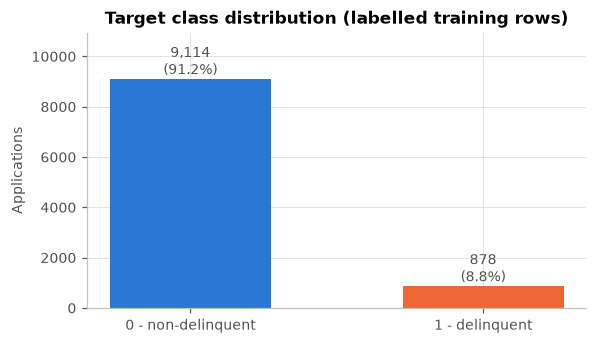

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 3.2))
bars = ax.bar(["0 - non-delinquent", "1 - delinquent"], dist["count"], color=[BLUE, ORANGE], width=0.55)
for b, (n, p) in zip(bars, dist[["count", "share_%"]].values):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n:,.0f}\n({p:.1f}%)", ha="center", va="bottom", color=INK)
ax.set_ylim(0, dist["count"].max() * 1.2)
ax.set_ylabel("Applications")
ax.set_title("Target class distribution (labelled training rows)")
plt.tight_layout(); plt.show()

In [8]:
# The 8 unlabelled rows: do they look otherwise normal?
train_raw.loc[~is_labelled, [ID_COL, "name", "Email Attributes.digitalAge", "Phone Network.currentNetworkName", "Mobile GIN.identityTrust"]]

,UID,name,Email Attributes.digitalAge,Phone Network.currentNetworkName,Mobile GIN.identityTrust
3332,3333,mithun govindaraju raj,0,Airtel,High
3981,3982,umamaheswara reddy patakota,0,Airtel,High
4529,4530,shashikant chandradev kumar,2411,Airtel,Medium
4785,4786,sanket sandeep ambre,2411,Airtel,Medium
6975,6976,jaswant singh kasana,2012,Airtel,Low
7091,7092,kalidass arumugam,407,Airtel,High
8227,8228,mohd shakeel,727,Airtel,Medium
9595,9596,hanumaiah ravikumar,2411,Airtel,Medium


In [9]:
# Is the target related to row order / UID? (would make UID a leaky feature)
uid_trend = (y.groupby(pd.qcut(train_raw.loc[is_labelled, ID_COL], 10, labels=[f"D{i}" for i in range(1, 11)]), observed=True)
               .agg(rows="size", bad_rate="mean"))
uid_trend["bad_rate"] = uid_trend["bad_rate"].round(3)
print("UID ranges: train", train_raw[ID_COL].min(), "-", train_raw[ID_COL].max(),
      "| test", test_raw[ID_COL].min(), "-", test_raw[ID_COL].max())
uid_trend.T

UID ranges: train 1 - 10000 | test 10001 - 15000


UID,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
rows,1000.000,999.00,999.000,999.000,999.000,999.000,999.000,999.000,999.000,1000.00
bad_rate,0.108,0.07,0.106,0.086,0.091,0.086,0.069,0.089,0.093,0.08


**Target, observed:**
* Format: stored as integers 0/1 plus the string `"NaT"` in **8 rows**. Those 8 rows have no label, so they are excluded from model training and validation.
* Class distribution: **9,114 good vs 878 bad (8.79% bad rate)**, an imbalance of about 10 : 1. Accuracy is therefore not a useful metric (predicting "all good" scores 91%). Ranking metrics (ROC-AUC, PR-AUC, KS) and stratified splitting are needed.
* Bad rate by UID decile moves between about 7% and 11% with no monotonic trend. UID is a sequential row ID (train 1–10,000, test 10,001–15,000). It will **not** be used as a feature.

## 4. Data types

The raw dtypes are misleading. Missing values are stored as the literal string `"NaT"`, so many numeric and 0/1 columns load as `object` with a mix of `int`, `float` and `str` values.

In [10]:
def type_profile(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for c in df.columns:
        s = df[c]
        types = s.map(lambda v: type(v).__name__).value_counts()
        rows.append({
            "column": c,
            "pandas_dtype": str(s.dtype),
            "python_types": ", ".join(f"{t}:{n}" for t, n in types.items()),
            "mixed_types": len(types) > 1,
            "n_unique": s.nunique(),
            "NaT_strings": int((s.astype(str).str.strip() == MISSING_TOKEN).sum()),
            "examples": list(s.dropna().astype(str).unique()[:4]),
        })
    return pd.DataFrame(rows)

tp = type_profile(train_raw)
print("pandas dtypes as loaded:", tp["pandas_dtype"].value_counts().to_dict())
print("Columns with mixed Python types:", tp["mixed_types"].sum())
tp.sort_values(["mixed_types", "NaT_strings"], ascending=False).reset_index(drop=True)

pandas dtypes as loaded: {'object': 50, 'int64': 23, 'str': 16, 'float64': 5}
Columns with mixed Python types: 50


,column,pandas_dtype,python_types,mixed_types,n_unique,NaT_strings,examples
0,Email Social Advance.paytm,object,"str:9978, int:22",True,3,9978,"[NaT, 0, 1]"
1,Phone Social Advance.paytm,object,"str:9974, int:26",True,3,9974,"[NaT, 1, 0]"
2,Email Social Advance.skype,object,"str:9661, int:339",True,3,9661,"[NaT, 0, 1]"
3,Phone Social Advance.skype,object,"str:9587, int:413",True,3,9587,"[NaT, 0, 1]"
4,Phone Network.portedFromNetworkcountryCodeIso2,object,"str:5299, int:4701",True,2,5299,"[91, NaT]"
5,Email Social Advance.pinterest,object,"int:9108, str:892",True,3,892,"[NaT, 0, 1]"
6,Email Social Advance.amazon,object,"int:9182, str:818",True,3,818,"[1, 0, NaT]"
7,Phone Social Advance.amazon,object,"int:9227, str:773",True,3,773,"[1, 0, NaT]"
8,Email Social Advance.zoho,object,"int:9306, str:694",True,3,694,"[0, 1, NaT]"
9,Phone Social Advance.zoho,object,"int:9307, str:693",True,3,693,"[0, NaT, 1]"


To work with the data I define the **semantic schema** explicitly and build a standardisation step:
`"NaT"` becomes a real missing value, numeric/flag columns are cast to numbers, ordinal text levels are kept as ordered labels, and text is trimmed.
`-1` sentinels are **kept as-is** at this stage because they mean "not found in Bureau network", which is information. They are analysed separately below.

In [11]:
PII_COLS = ["name", "Phone to Name.UPIname", "Email Name Attributes.phoneNumber"]
DATE_COLS = ["Email Attributes.domainUpdatedDate", "Phone Name Attributes.revocationMonth"]
ORDINAL_LEVELS = {   # low -> high, per the dictionary's meaning
    "Email Attributes.domainRiskLevel": ["Very Low", "Low", "Moderate", "High", "Very High"],   # "Review" = unrated
    "Email Attributes.emailFinalRecommendation": ["Bad", "Check", "Good"],                      # "No Data" = unrated
    "Email Attributes.footprint": ["NO_RECORDS", "LOW", "MEDIUM", "HIGH"],
    "Email Name Attributes.emailFootprintStrength": ["Very Low", "Low", "Medium", "High", "Very High"],
    "Phone Name Attributes.phoneFootprintStrengthOverall": ["Very Low", "Low", "Medium", "High", "Very High"],
    "Email GIN.identityTrust": ["Low", "Medium", "High"],
    "Mobile GIN.identityTrust": ["Low", "Medium", "High"],
}
NOMINAL_COLS = ["Email Attributes.domaincorporate", "Phone Network.currentNetworkName", "Phone Network.currentNetworkRegion",
                "Phone Network.numberBillingType", "Phone Network.portedFromNetworkName",
                "Phone Network.portedFromNetworkRegion", "Phone Network.portedFromNetworkcountryCodeIso2"]
TEXT_LIKE = PII_COLS[:2] + list(ORDINAL_LEVELS) + NOMINAL_COLS
OTHER_COLS = [c for c in FEATURES if c not in PII_COLS + DATE_COLS + TEXT_LIKE]


def standardise(df: pd.DataFrame) -> pd.DataFrame:
    """Turn the 'NaT' token into NaN and cast every column to its semantic type."""
    out = df.copy()
    for c in out.columns:
        s = out[c].astype(object)
        out[c] = s.mask(s.astype(str).str.strip() == MISSING_TOKEN)
    for c in OTHER_COLS + ["Email Name Attributes.phoneNumber"]:
        # raises if any non-numeric junk remains; float keeps train/test dtypes identical whether or not NaN is present
        out[c] = pd.to_numeric(out[c], errors="raise").astype(float)
    for c in DATE_COLS:
        out[c] = pd.to_datetime(out[c], errors="raise")
    for c in TEXT_LIKE:
        out[c] = out[c].astype("string").str.strip()
    return out


train_all = standardise(train_raw)
train = train_all.loc[is_labelled].copy()
train[TARGET] = y
test = standardise(test_raw)

BINARY_COLS = [c for c in OTHER_COLS if set(train_all[c].dropna().unique()) <= {0, 1}]
NUMERIC_COLS = [c for c in OTHER_COLS if c not in BINARY_COLS]

schema = pd.Series({**{c: "ID" for c in [ID_COL]}, **{c: "PII / free text" for c in PII_COLS},
                    **{c: "date" for c in DATE_COLS}, **{c: "ordinal categorical" for c in ORDINAL_LEVELS},
                    **{c: "nominal categorical" for c in NOMINAL_COLS}, **{c: "binary flag" for c in BINARY_COLS},
                    **{c: "numeric" for c in NUMERIC_COLS}}, name="semantic_type")
print("All non-'NaT' values converted cleanly (no coercion errors).")
print(schema.value_counts().to_string())
print("\nNumeric columns:", NUMERIC_COLS)

All non-'NaT' values converted cleanly (no coercion errors).
semantic_type
binary flag            53
numeric                20
ordinal categorical     7
nominal categorical     7
PII / free text         3
date                    2
ID                      1

Numeric columns: ['Email Attributes.digitalAge', 'Email Attributes.uniqueHits', 'Email Name Attributes.digitalage', 'Email Name Attributes.emailNameDigitalAge', 'Email Name Attributes.nameEmailMatch', 'Email Name Attributes.nameMatchScore', 'Email Name Attributes.ndrScore', 'Email Name Attributes.unrScore', 'Phone Name Attributes.digitalage', 'Phone Name Attributes.phoneNameDigitalAge', 'Email GIN.nameDiversity', 'Email GIN.l1Confidence', 'Email GIN.l1Count', 'Email GIN.l2Count', 'Email GIN.l2Confidence', 'Mobile GIN.nameDiversity', 'Mobile GIN.l1Confidence', 'Mobile GIN.l1Count', 'Mobile GIN.l2Count', 'Mobile GIN.l2Confidence']


In [12]:
# Category levels present in train vs test, for the text columns
pd.DataFrame({c: {"train_levels": sorted(train[c].dropna().unique().tolist()),
                  "test_levels_not_in_train": sorted(set(test[c].dropna()) - set(train[c].dropna()))}
              for c in list(ORDINAL_LEVELS) + NOMINAL_COLS}).T

,train_levels,test_levels_not_in_train
Email Attributes.domainRiskLevel,"[High, Low, Moderate, Review, Very High, Very Low]",[]
Email Attributes.emailFinalRecommendation,"[Bad, Check, Good, No Data]",[]
Email Attributes.footprint,"[HIGH, LOW, MEDIUM, NO_RECORDS]",[]
Email Name Attributes.emailFootprintStrength,"[High, Low, Very High, Very Low]",[]
Phone Name Attributes.phoneFootprintStrengthOverall,"[High, Low, Medium, Very High]",[]
Email GIN.identityTrust,"[High, Low, Medium]",[]
Mobile GIN.identityTrust,"[High, Low, Medium]",[]
Email Attributes.domaincorporate,"[No, Yes]",[]
Phone Network.currentNetworkName,"[Airtel, BSNL, IDEA, MTNL, Reliance Jio, Vodafone]",[]
Phone Network.currentNetworkRegion,"[Andhra Pradesh, Assam, Bihar and Jharkhand, Chennai, Delhi, Gujarat, Haryan...",[]


## 5. Missing values

There are three layers of missingness:
1. **Explicit NaN:** none. `isna()` on the raw files reports 0 everywhere, which is misleading.
2. **Hidden `"NaT"` tokens:** service returned nothing for that field.
3. **`-1` sentinel:** documented for `Email Attributes.digitalAge` ("absence of email in Bureau network") and used the same way in other digital-age / name-match fields.

In [13]:
print("Explicit NaN in raw train:", int(train_raw.isna().sum().sum()), "| raw test:", int(test_raw.isna().sum().sum()))

def missing_profile(df: pd.DataFrame) -> pd.DataFrame:
    nat = df[FEATURES].isna().mean()
    sent = df[FEATURES].apply(lambda s: pd.to_numeric(s, errors="coerce").eq(SENTINEL).mean())
    return pd.DataFrame({"NaT_%": 100 * nat, "minus1_%": 100 * sent, "effective_%": 100 * (nat + sent)})

mp = missing_profile(train).add_prefix("train_").join(missing_profile(test).add_prefix("test_"))
mp = mp[(mp > 0).any(axis=1)].sort_values("train_effective_%", ascending=False).round(2)
print(f"Columns with any NaT or -1: {len(mp)} of {len(FEATURES)}")
mp

Explicit NaN in raw train: 0 | raw test: 0


Columns with any NaT or -1: 63 of 92


,train_NaT_%,train_minus1_%,train_effective_%,test_NaT_%,test_minus1_%,test_effective_%
Email Attributes.domainUpdatedDate,100.00,0.0,100.0,100.00,0.0,100.0
Email Social Advance.paytm,99.78,0.0,99.779824,99.82,0.0,99.82
Phone Social Advance.paytm,99.74,0.0,99.739792,99.84,0.0,99.84
Phone Name Attributes.revocationMonth,98.80,0.0,98.799039,98.46,0.0,98.46
Email Social Advance.skype,96.61,0.0,96.607286,97.24,0.0,97.24
Phone Social Advance.skype,95.88,0.0,95.876701,96.12,0.0,96.12
Email Name Attributes.phoneNumber,0.00,84.207366,84.207366,0.00,88.32,88.32
Email Name Attributes.emailNameDigitalAge,0.02,80.404323,80.424339,0.04,84.96,85.0
Email Name Attributes.nameMatchScore,0.00,74.619696,74.619696,0.00,80.78,80.78
Email Name Attributes.ndrScore,0.00,74.049239,74.049239,0.00,80.26,80.26


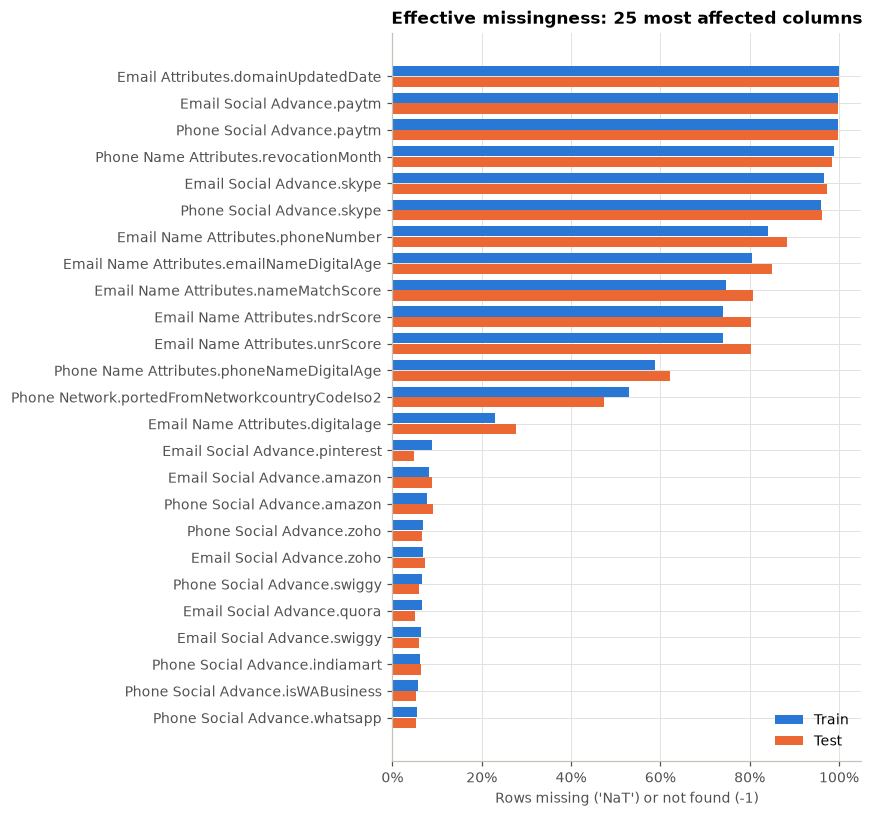

In [14]:
top = mp.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7.5))
pos = np.arange(len(top))
ax.barh(pos + 0.2, top["train_effective_%"], height=0.38, color=BLUE, label="Train")
ax.barh(pos - 0.2, top["test_effective_%"], height=0.38, color=ORANGE, label="Test")
ax.set_yticks(pos, top.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel("Rows missing ('NaT') or not found (-1)")
ax.set_title("Effective missingness: 25 most affected columns")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

**Missingness comes in blocks.** Whole services are absent together, so the missing values are *structural*, not random:

In [15]:
eff_missing = lambda df: df[FEATURES].isna() | df[FEATURES].apply(lambda s: pd.to_numeric(s, errors="coerce").eq(SENTINEL))
M = eff_missing(train)

blocks = {
    "Email GIN (9 graph columns)": [c for c in FEATURES if c.startswith("Email GIN.")],
    "Email-name match (nameMatchScore, ndr, unr, phoneNumber)": ["Email Name Attributes.nameMatchScore", "Email Name Attributes.ndrScore",
                                                                  "Email Name Attributes.unrScore", "Email Name Attributes.phoneNumber"],
    "Ported-from details (name, region, country)": ["Phone Network.portedFromNetworkName", "Phone Network.portedFromNetworkRegion",
                                                    "Phone Network.portedFromNetworkcountryCodeIso2"],
    "Email social flags (all 19)": [c for c in FEATURES if c.startswith("Email Social Advance.")],
    "Phone social flags (all 15)": [c for c in FEATURES if c.startswith("Phone Social Advance.")],
}
pd.DataFrame({name: {"rows_any_missing_%": 100 * M[cols].any(axis=1).mean(),
                     "rows_all_missing_%": 100 * M[cols].all(axis=1).mean()} for name, cols in blocks.items()}).T.round(2)

,rows_any_missing_%,rows_all_missing_%
Email GIN (9 graph columns),0.52,0.35
"Email-name match (nameMatchScore, ndr, unr, phoneNumber)",84.21,74.05
"Ported-from details (name, region, country)",58.43,53.01
Email social flags (all 19),99.87,0.00
Phone social flags (all 15),99.97,0.00


In [16]:
# Ported-from fields are *structurally* empty when the number was never ported
port = pd.crosstab(train["Phone Network.numberHasPortingHistory"],
                   train["Phone Network.portedFromNetworkName"].isna().map({True: "portedFrom missing", False: "portedFrom present"}))
port

Phone Network.portedFromNetworkName,portedFrom missing,portedFrom present
Phone Network.numberHasPortingHistory,,
0.0,5297,0
1.0,541,4154


**Is missingness informative?** Compare the bad rate when a field is missing / not found vs present. Fields where the gap is large should get an explicit missing-indicator (or a dedicated bin) instead of plain imputation.

In [17]:
overall_bad = train[TARGET].mean()
rows = []
for c in FEATURES:
    m = M[c]
    if m.sum() >= 30 and (~m).sum() >= 30:
        rows.append({"column": c, "n_missing": int(m.sum()), "bad_rate_missing": train.loc[m, TARGET].mean(),
                     "bad_rate_present": train.loc[~m, TARGET].mean()})
inf = pd.DataFrame(rows)
inf["lift_missing_vs_present"] = inf["bad_rate_missing"] / inf["bad_rate_present"]
inf.sort_values("lift_missing_vs_present", ascending=False).round(3).reset_index(drop=True)

,column,n_missing,bad_rate_missing,bad_rate_present,lift_missing_vs_present
0,Email Social Advance.skype,9653,0.090,0.027,3.391
1,Email Name Attributes.phoneNumber,8414,0.097,0.041,2.346
2,Email Name Attributes.emailNameDigitalAge,8036,0.098,0.045,2.185
3,Phone Social Advance.skype,9580,0.090,0.046,1.944
4,Phone Social Advance.instagram,30,0.167,0.088,1.902
5,Email Name Attributes.nameMatchScore,7456,0.099,0.055,1.808
6,Email Social Advance.jeevansaathi,212,0.156,0.086,1.802
7,Email Social Advance.flickr,51,0.157,0.088,1.792
8,Email Social Advance.toi,91,0.154,0.087,1.763
9,Email Name Attributes.unrScore,7399,0.099,0.056,1.757


## 6. Duplicate records and redundant columns

In [18]:
# NaN -> explicit "missing" label so comparisons treat missing values as equal (pandas 3 keeps NaN under astype(str))
as_text = lambda df: df.astype(object).where(df.notna(), "missing").astype(str)
key = lambda df: as_text(df[FEATURES])
print("Duplicate UIDs   - train:", train_raw[ID_COL].duplicated().sum(), "| test:", test_raw[ID_COL].duplicated().sum(),
      "| UIDs shared by train & test:", len(set(train_raw[ID_COL]) & set(test_raw[ID_COL])))
print("Exact duplicate rows (all features, ignoring UID/Target) - train:", key(train_all).duplicated().sum(),
      "| test:", key(test).duplicated().sum())
print("Exact feature-row matches between train and test:", key(train_all).merge(key(test), how="inner").shape[0])

norm_person = lambda df: df["name"].str.lower().str.split().str.join(" ")
print("\nRows sharing a name with another train row:", norm_person(train_all).duplicated(keep=False).sum())

# Same name AND same email / phone digital ages -> likely the same person applying twice
pkey = ["name", "Email Attributes.digitalAge", "Phone Name Attributes.digitalage", "Phone Network.currentNetworkRegion"]
person = lambda df: as_text(df.assign(name=norm_person(df))[pkey])
near = train_all[person(train_all).duplicated(keep=False)]
print("Likely repeat applicants within train (name + email age + phone age + region):", len(near), "rows")
print("Likely same applicant in both train and test:", person(train_all).merge(person(test).drop_duplicates(), how="inner").shape[0])
print("\nMost repeated names (common names, different people):")
norm_person(train_all).value_counts().head(5)

Duplicate UIDs   - train: 0 | test: 0 | UIDs shared by train & test: 0


Exact duplicate rows (all features, ignoring UID/Target) - train: 0 | test: 0


Exact feature-row matches between train and test: 0

Rows sharing a name with another train row: 1191
Likely repeat applicants within train (name + email age + phone age + region): 0 rows
Likely same applicant in both train and test: 0

Most repeated names (common names, different people):


name
amit kumar        30
rahul kumar       19
sunil kumar       18
sandeep kumar     17
abhishek kumar    15
Name: count, dtype: int64

In [19]:
# Columns that are exact copies of each other (after standardisation)
cols = [c for c in FEATURES if c not in PII_COLS]
fp = as_text(train_all[cols])
seen, dup_pairs = {}, []
for c in cols:
    sig = tuple(fp[c])
    if sig in seen:
        dup_pairs.append((seen[sig], c))
    else:
        seen[sig] = c
pd.DataFrame(dup_pairs, columns=["kept", "identical_copy"])

,kept,identical_copy
0,Email Name Attributes.businessNameDetected,Phone Name Attributes.businessNameDetected
1,Phone Network.isPhoneReachable,Phone Network.isValidPhoneNumber
2,Phone Name Attributes.ccrp,Phone Network.roaming
3,Email GIN.fraudCount,Email GIN.fraud
4,Phone Name Attributes.ccrp,Mobile GIN.fraudCount
5,Phone Name Attributes.ccrp,Mobile GIN.fraud


**Observed:** no duplicate UIDs, no duplicate feature rows and no train–test row overlap. 1,191 train rows share a name with another row, but these are common Indian names. **No pair** also shares the same email age, phone age and region, so there is no evidence of repeat applicants or train–test leakage through duplicates.

Identical columns:
* `Email Name Attributes.businessNameDetected` = `Phone Name Attributes.businessNameDetected` in every row. That is suspicious for two different services and suggests a pipeline/join issue. Keep one.
* `Email GIN.fraud` = `Email GIN.fraudCount`. Both are only ever 0 or missing; **no email in the data is flagged for fraud**.
* The remaining pairs are constant columns (next section).

## 7. Constant and near-constant columns

In [20]:
def dominance(df):
    txt = as_text(df[FEATURES])
    return pd.DataFrame({
        "n_unique_incl_missing": txt.nunique(),
        "top_value": txt.mode().iloc[0],
        "top_share_%": 100 * txt.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    })

dom = dominance(train_all).join(dominance(test)[["top_share_%"]].rename(columns={"top_share_%": "test_top_share_%"}))
dom = dom[dom["top_share_%"] >= 99].sort_values("top_share_%", ascending=False).round(2)
CONSTANT_COLS = dom.index[dom["n_unique_incl_missing"] == 1].tolist()
print("Constant in train (no information):", CONSTANT_COLS)
dom

Constant in train (no information): ['Email Attributes.domainUpdatedDate', 'Phone Network.isValidPhoneNumber', 'Phone Network.isPhoneReachable', 'Phone Name Attributes.ccrp', 'Mobile GIN.fraudCount', 'Mobile GIN.fraud', 'Phone Network.roaming']


,n_unique_incl_missing,top_value,top_share_%,test_top_share_%
Email Attributes.domainUpdatedDate,1,missing,100.00,100.00
Phone Network.isValidPhoneNumber,1,1.0,100.00,100.00
Phone Network.isPhoneReachable,1,1.0,100.00,100.00
Phone Name Attributes.ccrp,1,0.0,100.00,100.00
Mobile GIN.fraudCount,1,0.0,100.00,100.00
Mobile GIN.fraud,1,0.0,100.00,100.00
Phone Network.roaming,1,0.0,100.00,100.00
Mobile GIN.fraudNetwork,2,0.0,99.88,99.90
Email Social Advance.paytm,3,missing,99.78,99.82
Phone Social Advance.paytm,3,missing,99.74,99.84


The 7 constant columns (`Phone Name Attributes.ccrp`, `Phone Network.isPhoneReachable`, `isValidPhoneNumber`, `roaming`, `Mobile GIN.fraud`, `Mobile GIN.fraudCount`, `Email Attributes.domainUpdatedDate`) carry no information and will be dropped.
Several *fraud* flags are almost always 0 (`Email GIN.fraudNetwork` = 1 in only 7 rows, `Mobile GIN.fraudNetwork` in 11, `Email GIN.fraud` never). Bad rates on such tiny groups are unreliable, so these are low-value features unless combined into a broader flag.

## 8. Outliers and implausible values

Statistics below exclude the `-1` sentinel and missing values, so they describe genuine observations only.

In [21]:
def describe_numeric(df):
    rows = []
    for c in NUMERIC_COLS:
        v = df[c][df[c].notna() & df[c].ne(SENTINEL)]
        q1, q3 = v.quantile([0.25, 0.75])
        iqr = q3 - q1
        rows.append({"column": c, "n": len(v), "min": v.min(), "p1": v.quantile(.01), "median": v.median(),
                     "p99": v.quantile(.99), "max": v.max(), "skew": v.skew(),
                     "iqr_outlier_%": 100 * ((v < q1 - 1.5 * iqr) | (v > q3 + 1.5 * iqr)).mean(),
                     "other_negatives": int((df[c] < 0).sum() - df[c].eq(SENTINEL).sum())})
    return pd.DataFrame(rows).set_index("column")

describe_numeric(train).round(2)

,n,min,p1,median,p99,max,skew,iqr_outlier_%,other_negatives
column,,,,,,,,,
Email Attributes.digitalAge,9819,0.00,0.00,407.0,4740.92,7134.0,0.79,0.11,0
Email Attributes.uniqueHits,9992,0.00,0.00,7.0,16.00,26.0,0.28,0.77,0
Email Name Attributes.digitalage,7693,0.00,18.00,1778.0,4616.28,5730.0,0.73,2.57,0
Email Name Attributes.emailNameDigitalAge,1956,21.00,948.55,1790.0,4300.45,5717.0,1.48,7.21,0
Email Name Attributes.nameEmailMatch,9992,0.00,0.00,61.0,96.00,100.0,-0.66,0.00,0
Email Name Attributes.nameMatchScore,2536,6.00,13.00,91.0,100.00,100.0,-1.90,5.17,0
Email Name Attributes.ndrScore,2593,0.00,0.00,1.0,1.00,1.0,-3.77,6.90,0
Email Name Attributes.unrScore,2593,0.00,0.00,0.0,1.00,1.0,1.62,22.29,0
Phone Name Attributes.digitalage,9583,0.00,18.82,1799.0,4940.54,36411.0,3.95,2.48,0


In [22]:
# Domain plausibility rules
DAYS_30Y, DAYS_25Y = 30 * 365, 25 * 365
age_cols = [c for c in NUMERIC_COLS if "igital" in c or "DigitalAge" in c]
rules = {
    "Phone digital age > 30 years (mobile in India since 1995)": lambda d: d["Phone Name Attributes.digitalage"] > DAYS_30Y,
    "Phone+name age > 30 years": lambda d: d["Phone Name Attributes.phoneNameDigitalAge"] > DAYS_30Y,
    "Any email digital age > 25 years": lambda d: (d[[c for c in age_cols if "mail" in c]] > DAYS_25Y).any(axis=1),
    "Email GIN L1 count >= 100 (dictionary: >4 already risky)": lambda d: d["Email GIN.l1Count"] >= 100,
    "Email GIN L2 count >= 100": lambda d: d["Email GIN.l2Count"] >= 100,
    "Mobile GIN L2 count >= 100": lambda d: d["Mobile GIN.l2Count"] >= 100,
}
pd.DataFrame({r: {"train_rows": int(f(train_all).sum()), "test_rows": int(f(test).sum())} for r, f in rules.items()}).T

,train_rows,test_rows
Phone digital age > 30 years (mobile in India since 1995),1,0
Phone+name age > 30 years,0,0
Any email digital age > 25 years,0,0
Email GIN L1 count >= 100 (dictionary: >4 already risky),1,0
Email GIN L2 count >= 100,3,2
Mobile GIN L2 count >= 100,73,43


In [23]:
print("Values of the extreme graph counts (they cluster around ~500, i.e. a cap / placeholder rather than real counts):")
for c in ["Email GIN.l1Count", "Email GIN.l2Count", "Mobile GIN.l2Count"]:
    print(f"  {c:22s}", sorted(pd.concat([train_all[c], test[c]]).loc[lambda s: s >= 100].astype(int).tolist()))
print("Max phone digital age:", train_all["Phone Name Attributes.digitalage"].max(), "days =",
      round(train_all["Phone Name Attributes.digitalage"].max() / 365, 1), "years")

Values of the extreme graph counts (they cluster around ~500, i.e. a cap / placeholder rather than real counts):
  Email GIN.l1Count      [500]
  Email GIN.l2Count      [185, 192, 505, 505, 506]
  Mobile GIN.l2Count     [101, 101, 105, 108, 109, 110, 111, 116, 116, 116, 120, 134, 136, 137, 143, 144, 166, 169, 178, 181, 182, 190, 196, 202, 202, 213, 215, 216, 230, 242, 242, 255, 259, 267, 272, 283, 291, 311, 317, 318, 325, 337, 339, 352, 358, 359, 374, 393, 418, 437, 442, 445, 452, 461, 489, 496, 505, 505, 505, 505, 505, 505, 505, 505, 505, 505, 506, 506, 506, 506, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 507, 508, 508, 508, 508, 508, 508, 508, 508, 508, 509, 509, 510, 517]
Max phone digital age: 36411.0 days = 99.8 years


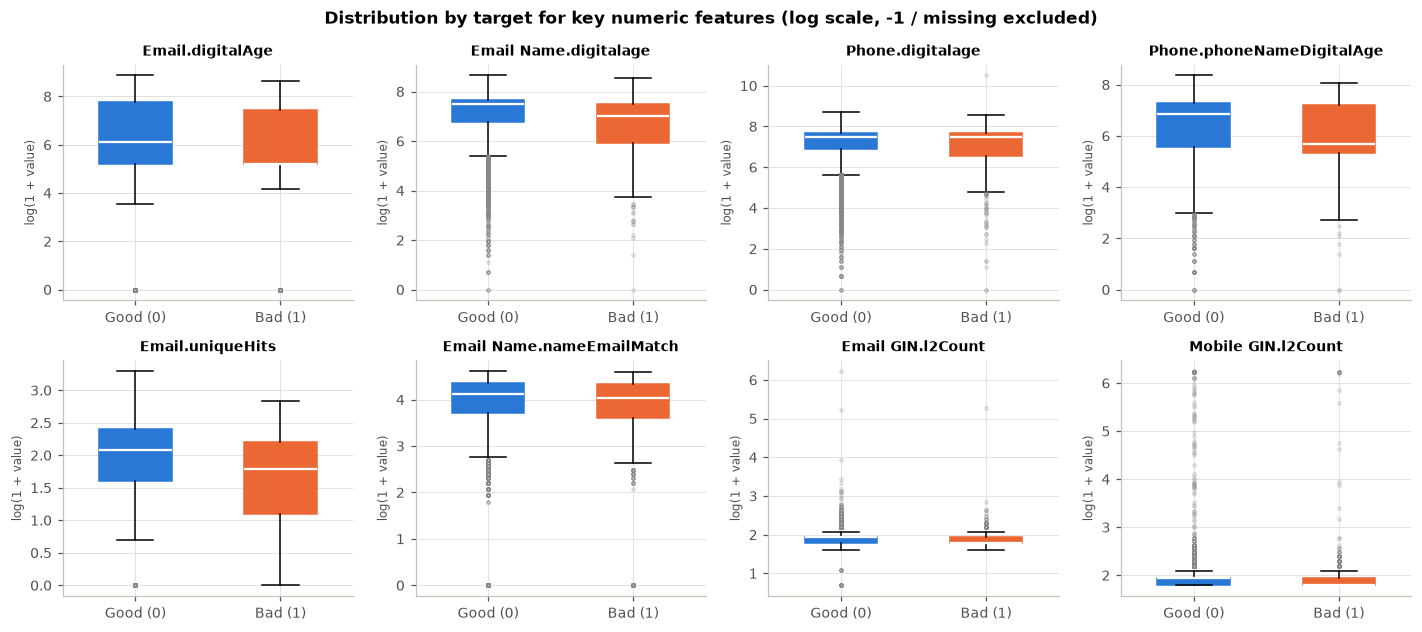

In [24]:
plot_cols = ["Email Attributes.digitalAge", "Email Name Attributes.digitalage", "Phone Name Attributes.digitalage",
             "Phone Name Attributes.phoneNameDigitalAge", "Email Attributes.uniqueHits", "Email Name Attributes.nameEmailMatch",
             "Email GIN.l2Count", "Mobile GIN.l2Count"]
fig, axes = plt.subplots(2, 4, figsize=(13, 5.8))
for ax, c in zip(axes.ravel(), plot_cols):
    data = [np.log1p(train.loc[(train[TARGET] == k) & train[c].ge(0), c]) for k in (0, 1)]
    bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=True,
                    flierprops=dict(marker="o", markersize=2, alpha=0.3, markeredgecolor=MUTED),
                    medianprops=dict(color="white", linewidth=1.5))
    for patch, col in zip(bp["boxes"], (BLUE, ORANGE)):
        patch.set_facecolor(col); patch.set_edgecolor(col)
    ax.set_xticks([1, 2], ["Good (0)", "Bad (1)"])
    ax.set_title(c.replace(" Attributes", "").replace("Phone Name", "Phone"), fontsize=9)
    ax.set_ylabel("log(1 + value)", fontsize=8)
fig.suptitle("Distribution by target for key numeric features (log scale, -1 / missing excluded)", fontweight="bold")
plt.tight_layout(); plt.show()

**Outlier observations:**
* Digital ages are strongly right-skewed (from 0 days to about 13–20 years) but mostly plausible. One phone digital age of **36,411 days (about 100 years)** is impossible and should be treated as an error (cap or set to missing).
* Graph link counts (`l1Count`, `l2Count`) have a small cluster of values around **500**. This looks like a system cap/placeholder rather than a real count. These are also the extreme "fraud-ring" profiles, so they should be **capped and flagged**, not deleted.
* IQR "outliers" in confidence/diversity scores are not errors. Those variables are bunched at 1.0, so any value below 1 is flagged by the IQR rule.
* Rows are **not dropped** for outliers. The plan is to winsorise / cap (or rely on tree-based models, which are insensitive to monotone scaling).

## 9. Logical consistency and text-field quality

In [25]:
email_age_gap = lambda d: (d["Email Attributes.digitalAge"] - d["Email Name Attributes.digitalage"]).abs()
checks = {
    "email+name link older than the email itself": lambda d: (d["Email Name Attributes.emailNameDigitalAge"] > d["Email Name Attributes.digitalage"]) & d["Email Name Attributes.digitalage"].ge(0),
    "phone+name link older than the phone itself": lambda d: (d["Phone Name Attributes.phoneNameDigitalAge"] > d["Phone Name Attributes.digitalage"]) & d["Phone Name Attributes.digitalage"].ge(0),
    "ported = 1 but ported-from network missing": lambda d: d["Phone Network.numberHasPortingHistory"].eq(1) & d["Phone Network.portedFromNetworkName"].isna(),
    "ported = 0 but ported-from network present": lambda d: d["Phone Network.numberHasPortingHistory"].eq(0) & d["Phone Network.portedFromNetworkName"].notna(),
    "revoked = 1 but revocation month missing": lambda d: d["Phone Name Attributes.revocationHistory"].eq(1) & d["Phone Name Attributes.revocationMonth"].isna(),
    "revoked = 0 but revocation month present": lambda d: d["Phone Name Attributes.revocationHistory"].eq(0) & d["Phone Name Attributes.revocationMonth"].notna(),
    "emailExists = 0 but email digital age > 0": lambda d: d["Email Attributes.emailExists"].eq(0) & d["Email Attributes.digitalAge"].gt(0),
    "two email-age fields differ by > 1 year (both found)": lambda d: (email_age_gap(d) > 365) & d["Email Attributes.digitalAge"].ge(0) & d["Email Name Attributes.digitalage"].ge(0),
}
pd.DataFrame({k: {"train_rows": int(f(train_all).sum()), "test_rows": int(f(test).sum())} for k, f in checks.items()}).T

,train_rows,test_rows
email+name link older than the email itself,5,3
phone+name link older than the phone itself,0,0
ported = 1 but ported-from network missing,543,247
ported = 0 but ported-from network present,0,0
revoked = 1 but revocation month missing,0,0
revoked = 0 but revocation month present,0,0
emailExists = 0 but email digital age > 0,0,0
two email-age fields differ by > 1 year (both found),6039,2653


In [26]:
both = train_all[["Email Attributes.digitalAge", "Email Name Attributes.digitalage"]].query("`Email Attributes.digitalAge` >= 0 and `Email Name Attributes.digitalage` >= 0")
print(f"Two 'email digital age' fields (both found, n={len(both)}): Spearman rho = {both.corr(method='spearman').iloc[0, 1]:.2f}, "
      f"identical in {both.iloc[:, 0].eq(both.iloc[:, 1]).mean():.1%} of rows")

# Text quality: applicant name vs name registered on UPI for the phone
clean_name = lambda s: s.str.lower().str.replace(r"[^a-z ]", " ", regex=True).str.split().str.join(" ")
upi, nm = train_all["Phone to Name.UPIname"], train_all["name"]
print(f"UPI name missing: {upi.isna().mean():.1%} (test {test['Phone to Name.UPIname'].isna().mean():.1%})")
raw_upi = train_raw["Phone to Name.UPIname"].astype(str)
print(f"UPI names with repeated / leading / trailing spaces (raw): {raw_upi.str.contains(r'\s{2,}|^\s|\s$', regex=True).mean():.1%}")
print(f"UPI names fully upper-case: {(upi == upi.str.upper()).mean():.1%}; containing non-letters: {upi.str.contains(r'[^A-Za-z ]', regex=True).mean():.1%}")
print(f"Exact match of normalised applicant name and UPI name: {(clean_name(nm) == clean_name(upi)).mean():.1%}")
print("Masked phone numbers (last 6 digits = 000000):",
      f"{train_all['Email Name Attributes.phoneNumber'].astype('Int64').astype(str).str.endswith('000000').mean():.1%} of rows; "
      f"-1 (not returned): {train_all['Email Name Attributes.phoneNumber'].eq(-1).mean():.1%}")
train_all.loc[clean_name(nm) != clean_name(upi), ["name", "Phone to Name.UPIname"]].dropna().head(8)

Two 'email digital age' fields (both found, n=7680): Spearman rho = 0.46, identical in 0.0% of rows
UPI name missing: 5.3% (test 0.6%)
UPI names with repeated / leading / trailing spaces (raw): 22.9%
UPI names fully upper-case: 31.6%; containing non-letters: 1.4%
Exact match of normalised applicant name and UPI name: 51.3%
Masked phone numbers (last 6 digits = 000000): 15.8% of rows; -1 (not returned): 84.2%


,name,Phone to Name.UPIname
3,harikrishna boganatham,BOGANATHAM HARIKRISHNA
6,ashokkumar natarajan,ASHOKKUMAR N
7,radhakrishnan vengatesh,VENGATESH R
8,rajeesh vazhayil,RAJEESH V
12,narender,Narender Kumar
13,narasimha murthy gurumurthy,Gurumurthy N
14,vazhekattil subi,SUBI V
15,kursida,Kursida Do Sarvar Ali


**Observed:** the records are largely internally consistent (porting, revocation and email-existence fields agree). Remaining issues:
* About 540 train rows say the number *was* ported but give no ported-from network. That is genuine missing data, unlike the structural blanks for never-ported numbers.
* The two "email digital age" fields from two services are never equal and only moderately correlated (Spearman about 0.46). They differ by more than a year in about 6,000 rows, so they measure different things (first seen in the network vs first seen with a name) and are separate signals, not duplicates.
* Name fields are messy (case, extra spaces, initials, reordered tokens, honorifics). Only about half match exactly after normalisation. A **fuzzy name-similarity score** between `name` and `UPIname` is a promising engineered feature. The raw names are PII and must not be used directly.
* `Email Name Attributes.phoneNumber` is masked (last 6 digits zeroed). It cannot be used as an identifier, and it is PII.

## 10. Train vs test distribution shift

If the test population differs from train, validation scores computed on train may overstate test performance. I measure the **Population Stability Index (PSI)** per feature. Numeric bins are train deciles, with `-1` and missing kept as separate bins.
Rule of thumb: PSI < 0.1 stable, 0.1–0.25 moderate shift, > 0.25 major shift.

In [27]:
def bucketise(s: pd.Series, ref: pd.Series, numeric: bool) -> pd.Series:
    """Map values to bins defined on `ref`; -1 and missing get their own bins."""
    if not numeric:
        return s.astype(object).where(s.notna(), "missing").astype(str)
    valid = ref[ref.notna() & ref.ne(SENTINEL)]
    edges = np.unique(valid.quantile(np.linspace(0.1, 0.9, 9)).values)
    out = pd.Series(np.searchsorted(edges, s.fillna(0), side="right"), index=s.index).map(lambda i: f"bin{i:02d}")
    out[s.eq(SENTINEL)] = "minus1"
    out[s.isna()] = "missing"
    return out


def psi(expected: pd.Series, actual: pd.Series, eps: float = 1e-4) -> float:
    p = expected.value_counts(normalize=True)
    q = actual.value_counts(normalize=True).reindex(p.index.union(actual.unique()), fill_value=0)
    p = p.reindex(q.index, fill_value=0)
    p, q = p + eps, q + eps
    return float(((q - p) * np.log(q / p)).sum())


MODEL_COLS = [c for c in FEATURES if c not in PII_COLS + DATE_COLS + CONSTANT_COLS]
psi_tbl = pd.Series({c: psi(bucketise(train_all[c], train_all[c], c in NUMERIC_COLS),
                            bucketise(test[c], train_all[c], c in NUMERIC_COLS)) for c in MODEL_COLS}, name="PSI")
psi_tbl = psi_tbl.sort_values(ascending=False).to_frame()
psi_tbl["shift"] = pd.cut(psi_tbl["PSI"], [-1, 0.1, 0.25, np.inf], labels=["stable", "moderate", "major"])
print(psi_tbl["shift"].value_counts().to_string())
med = lambda df: df[age_cols].where(df[age_cols].ge(0)).median()
print("\nMedian digital ages in days (found records only):")
print(pd.DataFrame({"train": med(train_all), "test": med(test)}).to_string())
psi_tbl.head(15).round(3)

shift
stable      78
major        2
moderate     1

Median digital ages in days (found records only):
                                            train    test
Email Attributes.digitalAge                 407.0   181.0
Email Name Attributes.digitalage           1778.0  1447.0
Email Name Attributes.emailNameDigitalAge  1790.0  1782.0
Phone Name Attributes.digitalage           1799.0  1799.5
Phone Name Attributes.phoneNameDigitalAge   797.5   301.0


,PSI,shift
Phone Network.currentNetworkName,1.562,major
Phone Network.numberBillingType,0.373,major
Phone Network.currentNetworkRegion,0.167,moderate
Email Attributes.digitalAge,0.077,stable
Phone Network.portedFromNetworkRegion,0.073,stable
Phone Network.portedFromNetworkName,0.056,stable
Email Attributes.uniqueHits,0.056,stable
Email Name Attributes.digitalage,0.039,stable
Email Attributes.footprint,0.032,stable
Email Social Advance.microsoft,0.031,stable


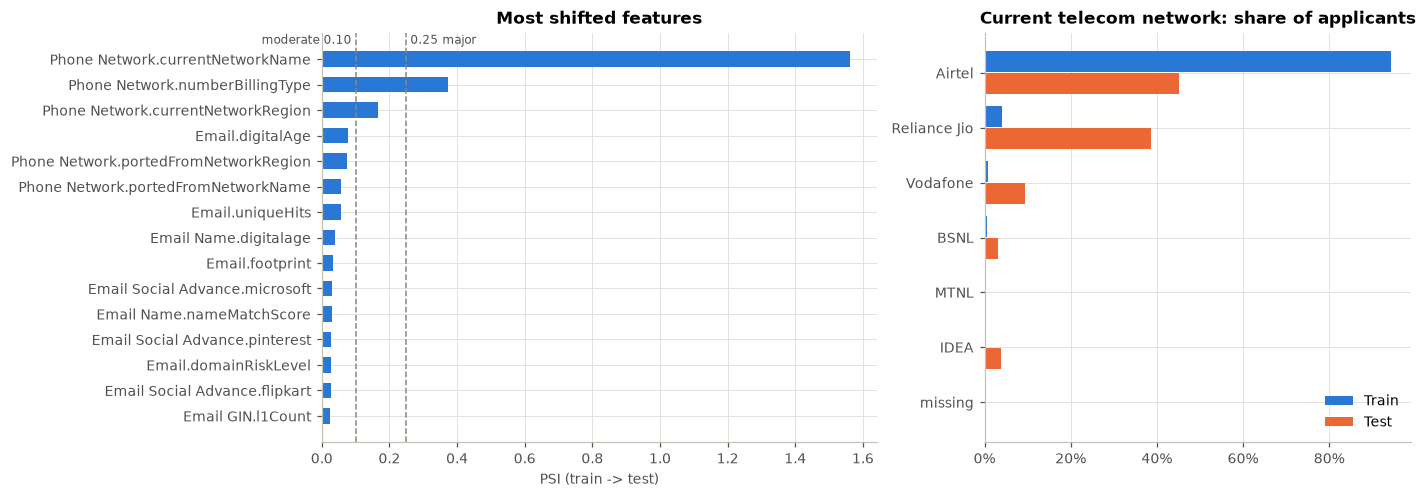

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
top = psi_tbl.head(15).iloc[::-1]
axes[0].barh(top.index.str.replace(" Attributes", ""), top["PSI"], color=BLUE, height=0.6)
for x, lab, ha in [(0.1, "moderate 0.10 ", "right"), (0.25, " 0.25 major", "left")]:
    axes[0].axvline(x, color=MUTED, linestyle="--", linewidth=1)
    axes[0].text(x, len(top) - 0.4, lab, color=INK, fontsize=8, ha=ha)
axes[0].set_xlabel("PSI (train -> test)")
axes[0].set_title("Most shifted features")

col = "Phone Network.currentNetworkName"
share = pd.DataFrame({"Train": train_all[col].fillna("missing").value_counts(normalize=True),
                      "Test": test[col].fillna("missing").value_counts(normalize=True)}).fillna(0).sort_values("Train")
pos = np.arange(len(share))
axes[1].barh(pos + 0.2, share["Train"], 0.38, color=BLUE, label="Train")
axes[1].barh(pos - 0.2, share["Test"], 0.38, color=ORANGE, label="Test")
axes[1].set_yticks(pos, share.index)
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set_title("Current telecom network: share of applicants")
axes[1].legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

**Observed:** the test set is **not** an i.i.d. sample of the training population.
* `Phone Network.currentNetworkName` shows a major shift: Airtel is about 94% of train but about 45% of test, and Reliance Jio grows from about 4% to about 39%. `currentNetworkRegion` and `numberBillingType` (missing 4% in train vs 23% in test) also shift.
* Typical digital ages are younger in test (median `Email Attributes.digitalAge` 407 → 181 days; `phoneNameDigitalAge` 798 → 301 days). Their decile-based PSI stays below 0.1, so this shift is milder than the telecom one.

Implications for later steps: carrier/region features may not generalise, and a train-only validation split will likely **overestimate** test performance. I will check these features' stability before relying on them, and keep this in mind when discussing limitations (it could reflect a different acquisition channel or time period).

## 11. First look at predictive signal

To connect data quality with business meaning, I compute each feature's **Information Value (IV)**, a standard screening measure in credit risk built from Weight-of-Evidence bins (missing and `-1` bins kept separate).
Rule of thumb: IV < 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, > 0.3 strong. This is a univariate screen only; it is not used for feature selection on its own.

In [29]:
def information_value(x: pd.Series, target: pd.Series, numeric: bool) -> float:
    b = bucketise(x, x, numeric)
    tab = pd.crosstab(b, target)
    good = (tab[0] + 0.5) / (tab[0].sum() + 0.5)
    bad = (tab[1] + 0.5) / (tab[1].sum() + 0.5)
    return float(((good - bad) * np.log(good / bad)).sum())

iv = pd.Series({c: information_value(train[c], train[TARGET], c in NUMERIC_COLS) for c in MODEL_COLS}, name="IV").sort_values(ascending=False)
iv_df = iv.to_frame().join(doc.set_index("column")[["feature_group", "impact_direction"]])
iv_df["strength"] = pd.cut(iv_df["IV"], [-1, 0.02, 0.1, 0.3, np.inf], labels=["useless", "weak", "medium", "strong"])
print(iv_df["strength"].value_counts().to_string())
iv_df.head(20).round(3)

strength
useless    41
weak       30
medium      9
strong      1


,IV,feature_group,impact_direction,strength
Phone Social Advance.whatsapp,0.306,Social,Binary indicator,strong
Email Name Attributes.digitalage,0.183,Identity,Higher is safer,medium
Email Attributes.digitalAge,0.175,Digital Footprint,Higher is safer,medium
Email Attributes.uniqueHits,0.175,Digital Footprint,Context dependent,medium
Phone Network.numberBillingType,0.145,Telecom,Context dependent,medium
Phone Network.currentNetworkRegion,0.131,Telecom,Context dependent,medium
Email Social Advance.amazon,0.130,Social,Binary indicator,medium
Email Attributes.footprint,0.126,Digital Footprint,Higher is safer,medium
Email Social Advance.flipkart,0.116,Social,Binary indicator,medium
Email Name Attributes.emailNameDigitalAge,0.101,Identity,Higher is safer,medium


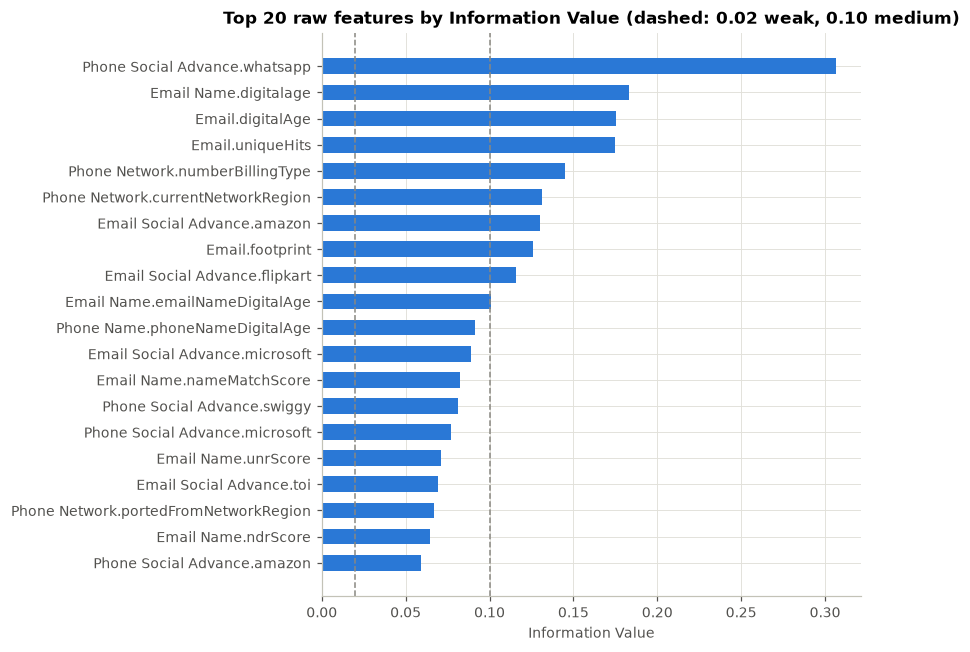

In [30]:
top = iv_df.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index.str.replace(" Attributes", ""), top["IV"], color=BLUE, height=0.6)
for x in (0.02, 0.1):
    ax.axvline(x, color=MUTED, linestyle="--", linewidth=1)
ax.set_xlabel("Information Value")
ax.set_title("Top 20 raw features by Information Value (dashed: 0.02 weak, 0.10 medium)")
plt.tight_layout(); plt.show()

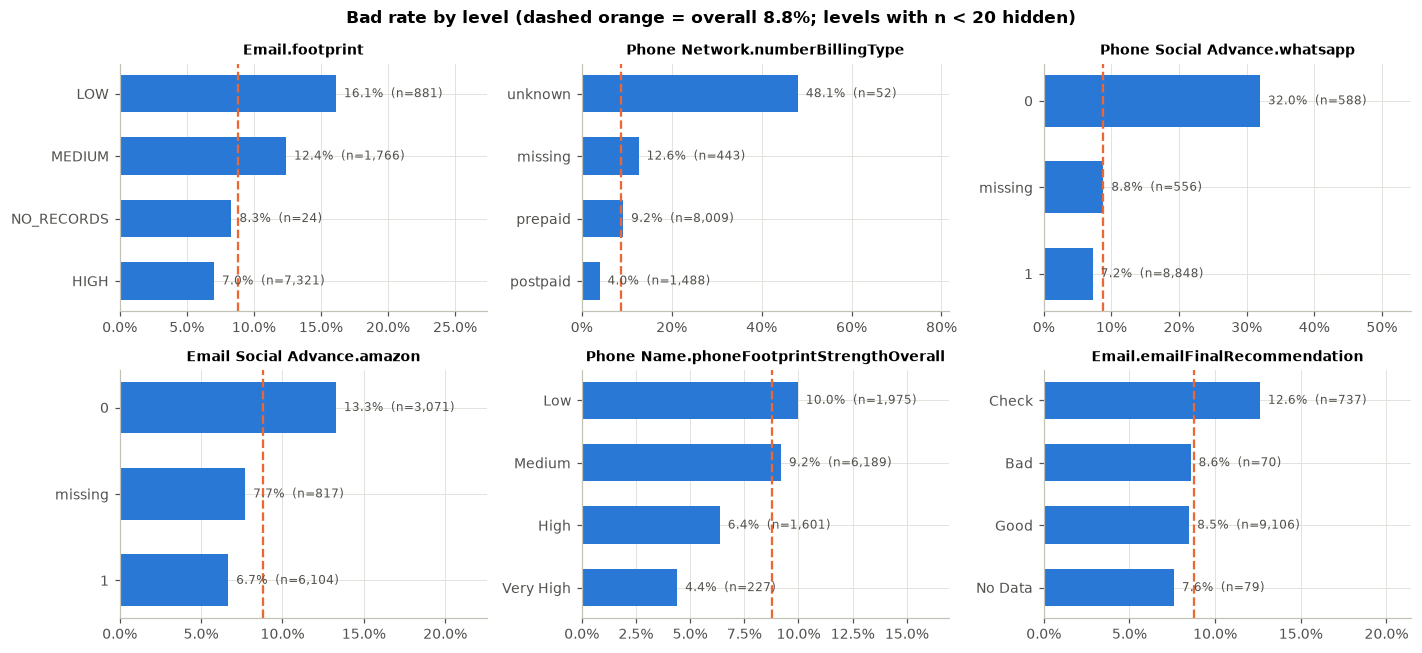

In [31]:
# Bad rate by level for key categorical / flag features (n shown per bar)
key_cats = ["Email Attributes.footprint", "Phone Network.numberBillingType", "Phone Social Advance.whatsapp",
            "Email Social Advance.amazon", "Phone Name Attributes.phoneFootprintStrengthOverall", "Email Attributes.emailFinalRecommendation"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), key_cats):
    level = train[c].map(lambda v: "missing" if pd.isna(v) else f"{v:g}" if isinstance(v, float) else str(v))
    g = train.groupby(level)[TARGET].agg(["size", "mean"])
    g = g[g["size"] >= 20].sort_values("mean")
    ax.barh(g.index, g["mean"], color=BLUE, height=0.6)
    ax.axvline(overall_bad, color=ORANGE, linewidth=1.5, linestyle="--")
    for i, (n, r) in enumerate(g[["size", "mean"]].values):
        ax.text(r, i, f"  {r:.1%}  (n={n:,.0f})", va="center", fontsize=8, color=INK)
    ax.set_xlim(0, g["mean"].max() * 1.7)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(c.replace(" Attributes", ""), fontsize=9)
fig.suptitle(f"Bad rate by level (dashed orange = overall {overall_bad:.1%}; levels with n < 20 hidden)", fontweight="bold")
plt.tight_layout(); plt.show()

**Does the data agree with the dictionary's expected direction?** Spearman correlation with Target on genuine values only (missing and `-1` excluded). *Higher is safer* should give a negative correlation; *Higher is riskier* a positive one.

In [32]:
ordinal_num = {c: train[c].map({lvl: i for i, lvl in enumerate(levels)}).astype(float) for c, levels in ORDINAL_LEVELS.items()}
rows = []
for c in NUMERIC_COLS + list(ORDINAL_LEVELS):
    exp = doc.set_index("column").loc[c, "impact_direction"]
    if exp not in ("Higher is safer", "Higher is riskier"):
        continue
    x = ordinal_num.get(c, train[c])
    ok = x.notna() & x.ne(SENTINEL) if c in NUMERIC_COLS else x.notna()
    rho = x[ok].corr(train.loc[ok, TARGET], method="spearman")
    rows.append({"column": c, "expected": exp, "n": int(ok.sum()), "spearman_vs_target": rho,
                 "agrees": (rho < 0) == (exp == "Higher is safer")})
pd.DataFrame(rows).sort_values("spearman_vs_target").round(3).reset_index(drop=True)

,column,expected,n,spearman_vs_target,agrees
0,Email Attributes.footprint,Higher is safer,9992,-0.106,True
1,Email Attributes.digitalAge,Higher is safer,9819,-0.093,True
2,Email Name Attributes.digitalage,Higher is safer,7693,-0.091,True
3,Phone Name Attributes.phoneNameDigitalAge,Higher is safer,4112,-0.078,True
4,Email Name Attributes.emailNameDigitalAge,Higher is safer,1956,-0.045,True
5,Phone Name Attributes.phoneFootprintStrengthOverall,Higher is safer,9992,-0.042,True
6,Email Name Attributes.emailFootprintStrength,Higher is safer,9992,-0.036,True
7,Email GIN.identityTrust,Higher is safer,9957,-0.030,True
8,Email GIN.l2Count,Higher is riskier,9955,-0.029,False
9,Mobile GIN.l1Count,Higher is riskier,9992,-0.028,False


**Observed signal (univariate, associational only, not causal):**
* The strongest raw signals are **digital-footprint / presence** variables: `Email Attributes.footprint` (LOW about 16% bad vs HIGH about 7%), `uniqueHits`, email digital age, and **platform presence** such as WhatsApp (not on WhatsApp: about 32% bad vs 7%) and Amazon.
* **Billing type** separates well (postpaid about 4% bad vs prepaid about 9%). The rare "unknown" level is very risky but small.
* Digital ages and footprint/trust levels agree with the dictionary's direction. The **graph (GIN) counts and confidences do not**: higher L1/L2 counts are very slightly *safer* here. Their correlations are close to zero (|ρ| < 0.03), so they carry little signal on their own.
* `nameMatchScore` is slightly positively related to delinquency among *found* records (ρ ≈ 0.04). Its useful signal is in the *not-found* (`-1`) state (bad rate 9.9% vs 5.5%). The same holds for the other email-name fields, so "was this identity found at all?" matters more than the score value.
* `currentNetworkRegion` has medium IV but shifts between train and test (Section 10), so its signal may not transfer.
* The direct fraud flags (`fraudNetwork`, `ccrp`) are too rare or constant to be useful. **This is a credit-delinquency problem, not a fraud problem.**
* Individually, most features are weak (IV < 0.1). Good performance will need **combined / aggregated features** (e.g. social-presence counts, footprint composites, identity-consistency scores), which motivates the feature-engineering step.

## 12. Summary of data-quality findings and implications

| # | Finding | Evidence | Treatment in the modelling pipeline |
|---|---|---|---|
| 1 | Target has 8 unlabelled rows (`"NaT"`) | 9,114 good / 878 bad / 8 NaT | Exclude from training & validation |
| 2 | Class imbalance, 8.8% bad (about 10:1) | Section 3 | Stratified splits; ROC-AUC, PR-AUC, KS rather than accuracy; class weights; deliberate threshold choice |
| 3 | Missing values hidden as the string `"NaT"`; raw dtypes wrong | 0 explicit NaN, but up to 100% `"NaT"` per column; 50 mixed-type columns | `standardise()` converts tokens to NaN and casts to semantic types |
| 4 | `-1` sentinel = "not found in Bureau network" | up to 84% of rows in email-name fields | Keep as information: missing-indicator flags / separate bin, not mean imputation |
| 5 | Missingness is structural and informative | Whole service blocks missing together; bad rate differs missing vs present | Block-level "service returned" flags; impute numerics after flagging |
| 6 | 7 constant columns; 2 non-constant identical pairs | Section 6–7 | Drop constants, `Phone Name Attributes.businessNameDetected` and `Email GIN.fraudCount` |
| 7 | Near-constant fraud flags | `Email GIN.fraudNetwork` = 1 in 7 rows, `Email GIN.fraud` never 1 | Low priority; may be folded into a combined risk flag |
| 8 | Implausible / capped values | Phone age of about 100 years; GIN counts about 500 | Cap at plausible limits / winsorise; flag extreme graph counts |
| 9 | No duplicate records or repeat applicants; no train–test overlap | Section 6 | No action needed |
| 10 | PII and identifier columns | `name`, `UPIname`, masked `phoneNumber`, `UID` | Never used raw; only derived non-identifying features (e.g. name-match similarity) |
| 11 | Major train→test shift | Carrier mix (Airtel 94% → 45%), billing-type missingness, younger digital ages | Check feature stability, avoid over-relying on carrier/region, flag as key limitation |
| 12 | No loan / repayment / income variables | Section 2 | Expect moderate discrimination; state as a limitation |

**Assumptions made:** `Target = 1` means delinquent (definition and observation window not provided); `-1` in age/score fields means "not found" (documented only for `Email Attributes.digitalAge`); interpretations of undocumented columns as listed in Section 2.

In [33]:
# Hand-off to feature engineering: cleaned frames and the column lists decided above
REDUNDANT_COLS = ["Phone Name Attributes.businessNameDetected", "Email GIN.fraudCount"]
DROP_COLS = [ID_COL] + PII_COLS + DATE_COLS + CONSTANT_COLS + REDUNDANT_COLS
BASE_FEATURES = [c for c in FEATURES if c not in DROP_COLS]
print(f"train (labelled): {train.shape}, test: {test.shape}")
print(f"Columns dropped as raw inputs: {len(set(DROP_COLS))}; base features carried forward: {len(BASE_FEATURES)}")
print("(revocationMonth is kept aside for feature engineering, e.g. 'months since number was recycled'.)")

train (labelled): (9992, 94), test: (5000, 93)
Columns dropped as raw inputs: 14; base features carried forward: 79
(revocationMonth is kept aside for feature engineering, e.g. 'months since number was recycled'.)


# Part 2 — Feature Engineering (3.2)

**Approach**
1. Every feature starts from a **risk hypothesis** (why it should relate to delinquency), not from trying every combination.
2. Every feature is **row-level and deterministic**. It uses only that applicant's own fields and fixed constants (no target values, no statistics learned from the data), so it is computed identically for train and test and cannot leak the target.
3. Each feature is checked **on the training data only** for: predictive strength (Information Value, bad rate by bin), whether the pattern is monotonic and matches the hypothesis, stability between train and test (PSI), and redundancy with the other features.
4. I keep a **small set (8 features)** and document the ideas I tested and rejected.

Feature names start with `fe_` so they are easy to tell apart from the original columns in the final output file.

## 13. Engineered features and their rationale

| # | Feature | How it is built | Why it may relate to delinquency |
|---|---|---|---|
| 1 | `fe_digital_presence_ratio` | Share of the checked platforms (19 email + 15 phone flags) where the applicant is registered. Missing flags are left out of the denominator. | **Aggregation.** Real, economically active people leave a broad footprint (shopping, food delivery, payments, professional sites). A thin presence suggests a new, secondary or synthetic identity and less economic activity. |
| 2 | `fe_email_tenure_days` | The **older** of the two independent email ages (Bureau network, email–name service); "not found" ignored. | **Combination.** Uses all available evidence of how long the email has existed and still works when one service misses it. A long-held email indicates a stable identity. |
| 3 | `fe_email_new_at_application` | 1 if the email was first seen ≤ 30 days ago. | **Derived flag.** An email that appears for the first time around the loan application is a classic sign of a throw-away or synthetic identity. |
| 4 | `fe_email_phone_age_gap_years` | Phone age − email age, in years. | **Consistency check.** A settled person usually has a phone and an email of similar vintage. A long-held phone paired with an email that appeared only recently suggests the email was created for the application. |
| 5 | `fe_phone_name_tenure_level` | 0 = no record of this name on this number, 1 = name linked ≤ 1 year, 2 = linked > 1 year. | **Binning of a skewed, mostly "not found" variable.** Measures how long the applicant has demonstrably *held* this number. Recently acquired or someone-else's numbers mean weaker identity assurance and contactability (important for collections). |
| 6 | `fe_identity_not_found_count` | Number of the 6 Bureau identity lookups (email age, email–name age, email–name link, name match, phone age, phone–name link) that returned "not found" (`-1`). | **Aggregation of the sentinel.** A "thin digital file", the identity counterpart of a thin credit file: less verifiable history means more uncertainty and more risk. |
| 7 | `fe_footprint_score` | Email footprint level (0–1) + phone footprint level (0–1), giving 0–2. | **Combination.** Merges Bureau's two separate footprint ratings into one identity-strength score. |
| 8 | `fe_is_postpaid` | 1 if the phone is on a postpaid plan. | **Domain flag.** Postpaid connections need stronger KYC and a telco credit check, and involve paying a monthly bill. They are a proxy for financial standing and payment discipline. *(Its share changes between train and test; see Section 18.)* |

**Kept as-is:** `Phone Social Advance.whatsapp` is the strongest single raw signal (Section 11). A phone not on WhatsApp in India is likely inactive or secondary, and the raw 0/1 flag already expresses that, so no transformation is needed.

In [34]:
EMAIL_SOCIAL = [c for c in FEATURES if c.startswith("Email Social Advance.")]
PHONE_SOCIAL = [c for c in FEATURES if c.startswith("Phone Social Advance.")]
IDENTITY_LOOKUPS = ["Email Attributes.digitalAge", "Email Name Attributes.digitalage", "Email Name Attributes.emailNameDigitalAge",
                    "Email Name Attributes.nameMatchScore", "Phone Name Attributes.digitalage", "Phone Name Attributes.phoneNameDigitalAge"]

# Fixed domain constants (not tuned on the target)
NEW_EMAIL_DAYS = 30                    # "first seen around the application"
ESTABLISHED_LINK_DAYS = 365            # phone held under this name for over a year
MAX_PLAUSIBLE_PHONE_AGE = 30 * 365     # mobile telephony in India started in 1995 (Section 8)


def found(s: pd.Series) -> pd.Series:
    """Treat the -1 'not found in Bureau network' code as missing."""
    return s.where(s.ne(SENTINEL))


def level_score(s: pd.Series, col: str) -> pd.Series:
    """Ordinal level scaled to 0-1 using the level order defined in Section 4."""
    levels = ORDINAL_LEVELS[col]
    return s.map({lvl: i / (len(levels) - 1) for i, lvl in enumerate(levels)}).astype(float)


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Build the 8 engineered features from a standardised frame (row-level, no fitted state)."""
    fe = pd.DataFrame(index=df.index)

    platforms = df[EMAIL_SOCIAL + PHONE_SOCIAL]
    fe["fe_digital_presence_ratio"] = platforms.sum(axis=1) / platforms.notna().sum(axis=1).replace(0, np.nan)

    email_tenure = pd.concat([found(df["Email Attributes.digitalAge"]), found(df["Email Name Attributes.digitalage"])], axis=1).max(axis=1)
    phone_age = found(df["Phone Name Attributes.digitalage"]).clip(upper=MAX_PLAUSIBLE_PHONE_AGE)
    fe["fe_email_tenure_days"] = email_tenure
    fe["fe_email_new_at_application"] = email_tenure.le(NEW_EMAIL_DAYS).astype(float)
    fe["fe_email_phone_age_gap_years"] = (phone_age - email_tenure) / 365

    link_days = found(df["Phone Name Attributes.phoneNameDigitalAge"])
    fe["fe_phone_name_tenure_level"] = np.select([link_days.isna(), link_days.le(ESTABLISHED_LINK_DAYS)], [0, 1], default=2).astype(float)

    fe["fe_identity_not_found_count"] = df[IDENTITY_LOOKUPS].eq(SENTINEL).sum(axis=1).astype(float)
    fe["fe_footprint_score"] = (level_score(df["Email Attributes.footprint"], "Email Attributes.footprint")
                                + level_score(df["Phone Name Attributes.phoneFootprintStrengthOverall"], "Phone Name Attributes.phoneFootprintStrengthOverall"))
    fe["fe_is_postpaid"] = df["Phone Network.numberBillingType"].eq("postpaid").fillna(False).astype(float)
    return fe


fe_train, fe_test = engineer_features(train), engineer_features(test)
ENGINEERED = fe_train.columns.tolist()
print(f"Engineered features: {len(ENGINEERED)} | train {fe_train.shape} | test {fe_test.shape}")
fe_train.describe().T.round(3)

Engineered features: 8 | train (9992, 8) | test (5000, 8)


,count,mean,std,min,25%,50%,75%,max
fe_digital_presence_ratio,9992.0,0.382,0.150,0.000,0.267,0.379,0.500,0.833
fe_email_tenure_days,9832.0,1593.671,1215.772,0.000,370.750,1740.000,2411.000,7134.000
fe_email_new_at_application,9992.0,0.037,0.188,0.000,0.000,0.000,0.000,1.000
fe_email_phone_age_gap_years,9436.0,0.074,4.204,-14.759,-2.532,-0.355,3.422,17.219
fe_phone_name_tenure_level,9992.0,0.619,0.807,0.000,0.000,0.000,1.000,2.000
fe_identity_not_found_count,9992.0,2.426,1.328,0.000,2.000,3.000,3.000,6.000
fe_footprint_score,9992.0,1.382,0.293,0.250,1.250,1.500,1.500,2.000
fe_is_postpaid,9992.0,0.149,0.356,0.000,0.000,0.000,0.000,1.000


**A note on email age.** The email digital age has heavy "pile-ups" on single values. These look like system dates (the date a data partner was onboarded), not true first-use dates. This is why `fe_email_tenure_days` takes the older of the two email ages, and why "new email" uses a low threshold (≤ 30 days) well below the 181-day pile-up.
The bad rate for "new email" is about the same at 30, 90 or 180 days, so the threshold is not fine-tuned.

In [35]:
ea = train["Email Attributes.digitalAge"]
pile = ea.value_counts().head(5).rename("rows").to_frame()
pile["share_%"] = (100 * pile["rows"] / len(train)).round(1)
pile["bad_rate"] = train.groupby(ea)[TARGET].mean().reindex(pile.index).round(3)
print("Most frequent Email Attributes.digitalAge values (train):")
display(pile)

tenure = fe_train["fe_email_tenure_days"]
pd.DataFrame({f"<= {d} days": {"rows": int(tenure.le(d).sum()), "bad_rate": round(train.loc[tenure.le(d), TARGET].mean(), 3),
                               "bad_rate_rest": round(train.loc[~tenure.le(d), TARGET].mean(), 3)} for d in (30, 90, 180)}).T

Most frequent Email Attributes.digitalAge values (train):


,rows,share_%,bad_rate
Email Attributes.digitalAge,,,
181.0,3663,36.7,0.094
2411.0,1673,16.7,0.065
0.0,601,6.0,0.183
407.0,509,5.1,0.084
2378.0,317,3.2,0.047


,rows,bad_rate,bad_rate_rest
<= 30 days,368.0,0.185,0.084
<= 90 days,386.0,0.184,0.084
<= 180 days,406.0,0.182,0.084


## 14. Evaluating the engineered features (training data only)

For each feature: Information Value (IV), the best IV among the raw columns it is built from (did combining help?), train→test stability (PSI), whether the bad rate moves strictly in one direction across bins, and missingness.
Continuous features are split into train quintiles; discrete ones use their own levels. Missing values get their own bin.

In [36]:
def fe_bins(x: pd.Series, ref: pd.Series, q: int = 5) -> pd.Series:
    """Ordered bins defined on `ref` (train). Discrete features keep their levels; missing gets its own bin."""
    if ref.nunique() <= 10:
        levels = sorted(ref.dropna().unique())
        labels = [f"{v:g}" for v in levels]
        out = x.map(dict(zip(levels, labels)))
    else:
        edges = np.unique(ref.dropna().quantile(np.linspace(0, 1, q + 1)[1:-1]).values)
        fmt = lambda v: f"{v:,.0f}" if abs(v) >= 100 else f"{v:.3g}"
        labels = [f"<= {fmt(edges[0])}"] + [f"{fmt(a)} - {fmt(b)}" for a, b in zip(edges[:-1], edges[1:])] + [f"> {fmt(edges[-1])}"]
        out = pd.Series(np.array(labels, dtype=object)[np.searchsorted(edges, x.fillna(0), side="left")], index=x.index)
    out = out.where(x.notna(), "missing")
    return pd.Series(pd.Categorical(out, categories=labels + ["missing"], ordered=True), index=x.index)


def iv_from_bins(b: pd.Series, target: pd.Series) -> float:
    tab = pd.crosstab(b, target)
    good, bad = (tab[0] + 0.5) / (tab[0].sum() + 0.5), (tab[1] + 0.5) / (tab[1].sum() + 0.5)
    return float(((good - bad) * np.log(good / bad)).sum())


PARENTS = {
    "fe_digital_presence_ratio": EMAIL_SOCIAL + PHONE_SOCIAL,
    "fe_email_tenure_days": ["Email Attributes.digitalAge", "Email Name Attributes.digitalage"],
    "fe_email_new_at_application": ["Email Attributes.digitalAge", "Email Name Attributes.digitalage"],
    "fe_email_phone_age_gap_years": ["Email Attributes.digitalAge", "Email Name Attributes.digitalage", "Phone Name Attributes.digitalage"],
    "fe_phone_name_tenure_level": ["Phone Name Attributes.phoneNameDigitalAge"],
    "fe_identity_not_found_count": IDENTITY_LOOKUPS,
    "fe_footprint_score": ["Email Attributes.footprint", "Phone Name Attributes.phoneFootprintStrengthOverall"],
    "fe_is_postpaid": ["Phone Network.numberBillingType"],
}
rows = []
for c in ENGINEERED:
    b_tr, b_te = fe_bins(fe_train[c], fe_train[c]), fe_bins(fe_test[c], fe_train[c])
    rates = train[TARGET].groupby(b_tr, observed=True).mean().drop("missing", errors="ignore")
    steps = np.sign(np.diff(rates.values))
    rows.append({"feature": c, "IV": iv_from_bins(b_tr, train[TARGET]), "best_parent_IV": iv.reindex(PARENTS[c]).max(),
                 "PSI_train_to_test": psi(b_tr.astype(str), b_te.astype(str)),
                 "spearman_vs_target": fe_train[c].corr(train[TARGET], method="spearman"),
                 "strictly_monotonic": bool(len(steps) and (np.all(steps >= 0) or np.all(steps <= 0))),
                 "missing_%": 100 * fe_train[c].isna().mean()})
fe_eval = pd.DataFrame(rows).set_index("feature").round(3)
fe_eval

,IV,best_parent_IV,PSI_train_to_test,spearman_vs_target,strictly_monotonic,missing_%
feature,,,,,,
fe_digital_presence_ratio,0.212,0.306,0.026,-0.127,False,0.000
fe_email_tenure_days,0.194,0.183,0.068,-0.120,True,1.601
fe_email_new_at_application,0.041,0.183,0.008,0.067,True,0.000
fe_email_phone_age_gap_years,0.117,0.183,0.028,0.088,True,5.564
fe_phone_name_tenure_level,0.083,0.091,0.013,-0.070,True,0.000
fe_identity_not_found_count,0.138,0.183,0.026,0.097,False,0.000
fe_footprint_score,0.129,0.126,0.027,-0.096,True,0.000
fe_is_postpaid,0.084,0.145,0.059,-0.071,True,0.000


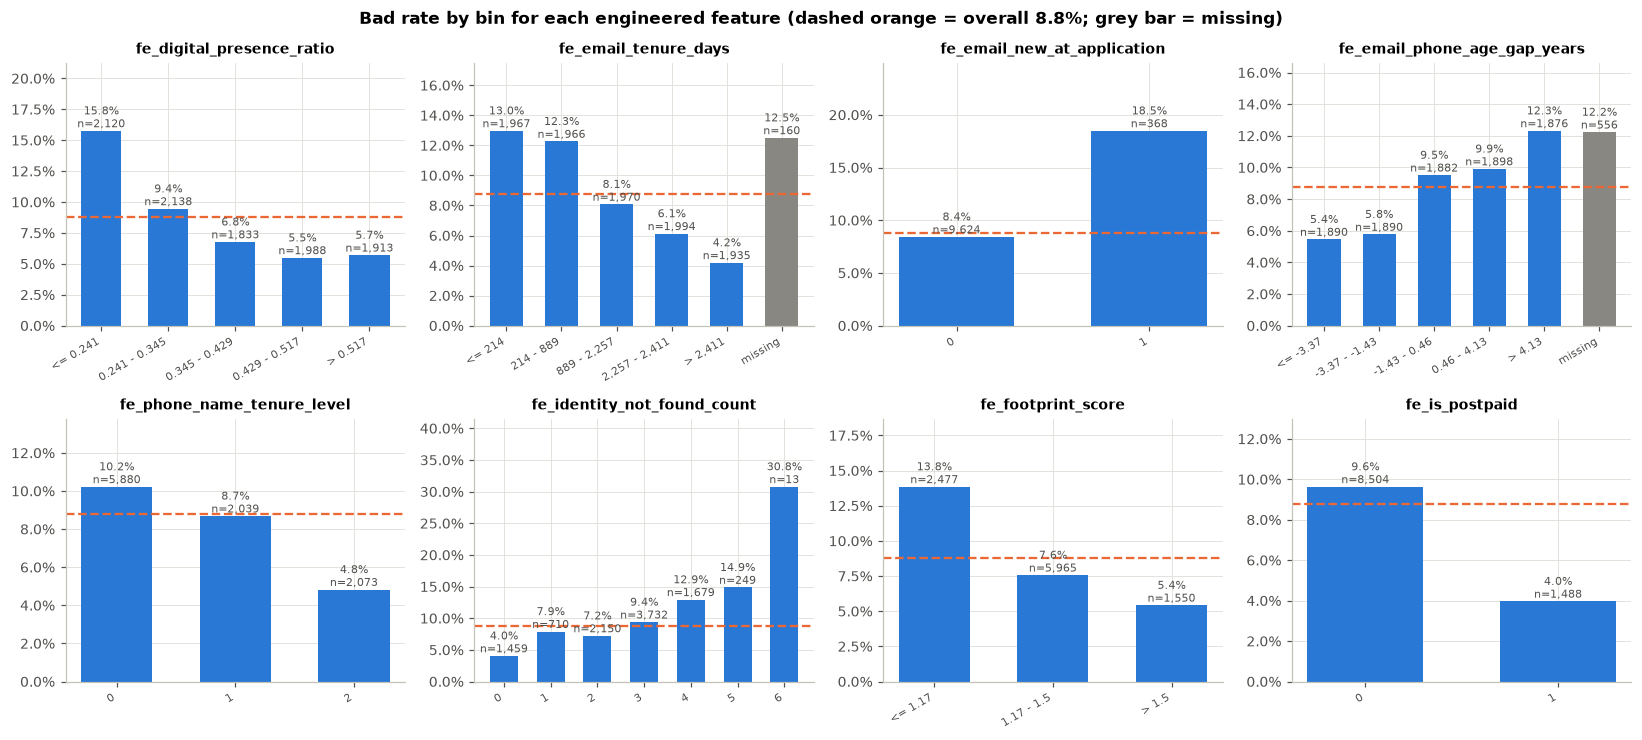

In [37]:
overall_bad = train[TARGET].mean()
fig, axes = plt.subplots(2, 4, figsize=(15, 6.8))
for ax, c in zip(axes.ravel(), ENGINEERED):
    b = fe_bins(fe_train[c], fe_train[c])
    g = train[TARGET].groupby(b, observed=True).agg(["size", "mean"])
    ax.bar(range(len(g)), g["mean"], color=[MUTED if i == "missing" else BLUE for i in g.index], width=0.6)
    ax.axhline(overall_bad, color=ORANGE, linestyle="--", linewidth=1.5)
    for i, (n, r) in enumerate(g[["size", "mean"]].values):
        ax.text(i, r, f"{r:.1%}\nn={n:,.0f}", ha="center", va="bottom", fontsize=7, color=INK)
    ax.set_xticks(range(len(g)), g.index, rotation=30, ha="right", fontsize=7)
    ax.set_ylim(0, g["mean"].max() * 1.35)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(c, fontsize=9)
fig.suptitle(f"Bad rate by bin for each engineered feature (dashed orange = overall {overall_bad:.1%}; grey bar = missing)", fontweight="bold")
plt.tight_layout(); plt.show()

In [38]:
# Redundancy: rank correlation between the engineered features (and the WhatsApp flag kept as-is)
corr = fe_train.join(train["Phone Social Advance.whatsapp"].rename("whatsapp (raw)")).corr(method="spearman").round(2)
corr

,fe_digital_presence_ratio,fe_email_tenure_days,fe_email_new_at_application,fe_email_phone_age_gap_years,fe_phone_name_tenure_level,fe_identity_not_found_count,fe_footprint_score,fe_is_postpaid,whatsapp (raw)
fe_digital_presence_ratio,1.00,0.54,-0.28,-0.43,0.33,-0.52,0.67,0.21,0.16
fe_email_tenure_days,0.54,1.00,-0.33,-0.76,0.29,-0.62,0.46,0.21,0.05
fe_email_new_at_application,-0.28,-0.33,1.00,0.21,-0.08,0.23,-0.32,-0.05,-0.03
fe_email_phone_age_gap_years,-0.43,-0.76,0.21,1.00,-0.40,0.59,-0.37,-0.15,-0.05
fe_phone_name_tenure_level,0.33,0.29,-0.08,-0.40,1.00,-0.71,0.39,0.19,0.07
fe_identity_not_found_count,-0.52,-0.62,0.23,0.59,-0.71,1.00,-0.51,-0.21,-0.06
fe_footprint_score,0.67,0.46,-0.32,-0.37,0.39,-0.51,1.00,0.16,0.07
fe_is_postpaid,0.21,0.21,-0.05,-0.15,0.19,-0.21,0.16,1.00,0.07
whatsapp (raw),0.16,0.05,-0.03,-0.05,0.07,-0.06,0.07,0.07,1.00


## 15. Ideas tested and rejected

Recording negative results is part of "prioritising a small set of well-motivated features". These ideas were plausible but did not earn a place:

In [39]:
def name_tokens(s: pd.Series) -> pd.Series:
    return s.fillna("").str.lower().str.replace(r"[^a-z ]", " ", regex=True).str.split()


def token_match_share(a: list, b: list) -> float:
    """Share of tokens in `a` found in `b`; single letters match as initials."""
    if not a or not b:
        return np.nan
    hits = sum(t in b or any(x[0] == t[0] and (len(t) == 1 or len(x) == 1) for x in b) for t in a)
    return hits / len(a)


def rejected_candidates(df: pd.DataFrame) -> pd.DataFrame:
    out = pd.DataFrame(index=df.index)
    a, b = name_tokens(df["name"]), name_tokens(df["Phone to Name.UPIname"])
    out["upi_name_similarity"] = [(token_match_share(x, y) + token_match_share(y, x)) / 2 if x and y else np.nan for x, y in zip(a, b)]
    commerce = [c for c in EMAIL_SOCIAL + PHONE_SOCIAL if c.split(".")[1] in ("amazon", "flipkart", "swiggy", "paytm", "indiamart", "housing", "yatra")]
    out["commerce_platform_count"] = df[commerce].sum(axis=1)
    out["ported_across_circles"] = (df["Phone Network.numberHasPortingHistory"].eq(1)
                                    & df["Phone Network.portedFromNetworkRegion"].notna()
                                    & df["Phone Network.portedFromNetworkRegion"].ne(df["Phone Network.currentNetworkRegion"])).fillna(False).astype(float)
    out["extreme_graph_links"] = (df[["Email GIN.l1Count", "Email GIN.l2Count", "Mobile GIN.l2Count"]] >= 100).any(axis=1).astype(float)
    return out


rej_tr, rej_te = rejected_candidates(train), rejected_candidates(test)
reasons = {
    "upi_name_similarity": "No signal: applicant name vs UPI-registered name similarity barely differs between good and bad borrowers; also shifts train->test",
    "commerce_platform_count": "Redundant: almost the same information as fe_digital_presence_ratio",
    "ported_across_circles": "Weak signal, and relies on region fields that are unstable and could act as geographic proxies",
    "extreme_graph_links": "No signal: identity-graph link counts are unrelated to delinquency here",
}
pd.DataFrame({c: {"IV": iv_from_bins(fe_bins(rej_tr[c], rej_tr[c]), train[TARGET]),
                  "PSI": psi(fe_bins(rej_tr[c], rej_tr[c]).astype(str), fe_bins(rej_te[c], rej_tr[c]).astype(str)),
                  "max_|rho|_with_kept": fe_train.corrwith(rej_tr[c], method="spearman").abs().max(),
                  "reason": reasons[c]} for c in rej_tr}).T

,IV,PSI,max_|rho|_with_kept,reason
upi_name_similarity,0.001604,0.100502,0.12492,No signal: applicant name vs UPI-registered name similarity barely differs b...
commerce_platform_count,0.172958,0.016216,0.833837,Redundant: almost the same information as fe_digital_presence_ratio
ported_across_circles,0.022665,0.004125,0.082307,"Weak signal, and relies on region fields that are unstable and could act as ..."
extreme_graph_links,0.006708,0.000234,0.023291,No signal: identity-graph link counts are unrelated to delinquency here


## 16. Transformations and the model-ready feature matrix

Transformations applied to the raw inputs before modelling:

| Transformation | Applied to | Reason |
|---|---|---|
| `-1` → missing | All numeric Bureau fields | `-1` is a code, not a quantity. Treating it as a number would put "not found" just below "0 days old". The "not found" information is kept through `fe_identity_not_found_count` and the models' missing-value handling. |
| Ordinal encoding | 7 level variables (footprint, trust, risk level, recommendation) | Keeps their natural order (Low < Medium < High). Unrated levels ("Review", "No Data") become missing. |
| Capping | `Phone Name Attributes.digitalage` at 30 years | Removes the impossible 100-year value (Section 8). |
| Categories fixed from train | Remaining nominal fields (billing type, ported-from network, domain corporate, ported-from country) | Train and test get identical category codes. |
| Excluded | `currentNetworkName`, `currentNetworkRegion`, `portedFromNetworkRegion` | Carrier mix shifts hugely between train and test (PSI 1.56), so learned carrier effects would not transfer. Region fields are unstable and could act as **geographic proxies** that raise fairness concerns, with no clear causal link to repayment. |

Log transforms of the skewed tenure features are left to the model pipeline: tree models do not need them, and a linear model will apply them inside its own pipeline.

In [40]:
EXCLUDED_UNSTABLE = ["Phone Network.currentNetworkName", "Phone Network.currentNetworkRegion", "Phone Network.portedFromNetworkRegion"]
NOMINAL_CATEGORIES = {c: sorted(train[c].dropna().unique()) for c in NOMINAL_COLS}   # learned from train only
RAW_MODEL_COLS = [c for c in BASE_FEATURES if c not in EXCLUDED_UNSTABLE]


def build_model_matrix(df: pd.DataFrame) -> pd.DataFrame:
    """Raw inputs after the transformations above, plus the engineered features."""
    X = pd.DataFrame(index=df.index)
    for c in RAW_MODEL_COLS:
        if c in ORDINAL_LEVELS:
            X[c] = df[c].map({lvl: i for i, lvl in enumerate(ORDINAL_LEVELS[c])}).astype(float)
        elif c in NOMINAL_COLS:
            X[c] = pd.Categorical(df[c].astype(object).where(df[c].notna(), np.nan), categories=NOMINAL_CATEGORIES[c])
        elif c in NUMERIC_COLS:
            X[c] = found(df[c])
        else:
            X[c] = df[c]
    X["Phone Name Attributes.digitalage"] = X["Phone Name Attributes.digitalage"].clip(upper=MAX_PLAUSIBLE_PHONE_AGE)
    return pd.concat([X, engineer_features(df)], axis=1)


X_train, X_test = build_model_matrix(train), build_model_matrix(test)
y_train = train[TARGET]

assert list(X_train.columns) == list(X_test.columns), "train/test columns differ"
assert X_test.index.equals(test_raw.index) and len(X_test) == len(test_raw), "test rows lost or reordered"
print(f"X_train {X_train.shape} | X_test {X_test.shape} | y_train bad rate {y_train.mean():.2%}")
print(f"Raw inputs kept: {len(RAW_MODEL_COLS)} | engineered: {len(ENGINEERED)} | excluded for instability: {len(EXCLUDED_UNSTABLE)}")
print("Column types:", X_train.dtypes.astype(str).value_counts().to_dict())

X_train (9992, 84) | X_test (5000, 84) | y_train bad rate 8.79%
Raw inputs kept: 76 | engineered: 8 | excluded for instability: 3
Column types: {'float64': 80, 'category': 4}


## 17. Do the engineered features add value?

A quick check before full modelling (Section 3.3): repeated stratified 5-fold cross-validation (3 repeats) **on the training data only**, ROC-AUC.
* **Gradient boosting** (handles missing values and non-linear effects natively): raw features vs raw + engineered.
* **Logistic regression** (simple, interpretable): all ~70 raw numeric/ordinal columns vs **only the 8 engineered features + the WhatsApp flag**.

The model settings are deliberately plain and untuned; this is only a relative comparison.

In [41]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
gbm = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=40,
                                     l2_regularization=1.0, categorical_features="from_dtype", early_stopping=False,
                                     random_state=RANDOM_STATE)
logit = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                      LogisticRegression(C=0.5, max_iter=2000))
signed_log = FunctionTransformer(lambda d: np.sign(d) * np.log1p(np.abs(d)), feature_names_out="one-to-one")
logit_log = make_pipeline(signed_log, SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                          LogisticRegression(C=0.5, max_iter=2000))

raw_cols = [c for c in X_train.columns if c not in ENGINEERED]
raw_numeric = [c for c in raw_cols if c not in NOMINAL_COLS]
compact = ENGINEERED + ["Phone Social Advance.whatsapp"]

experiments = [
    ("Gradient boosting", "raw features", gbm, X_train[raw_cols]),
    ("Gradient boosting", "raw + 8 engineered", gbm, X_train),
    ("Logistic regression", "raw numeric/ordinal", logit, X_train[raw_numeric]),
    ("Logistic regression", "8 engineered + WhatsApp flag", logit_log, X_train[compact]),
]
res = []
for model_name, feat_name, model, X in experiments:
    s = cross_val_score(model, X, y_train, cv=cv, scoring="roc_auc")
    res.append({"model": model_name, "features": feat_name, "n_features": X.shape[1], "AUC_mean": s.mean(), "AUC_std": s.std()})
pd.DataFrame(res).round(4)

,model,features,n_features,AUC_mean,AUC_std
0,Gradient boosting,raw features,76,0.6979,0.0184
1,Gradient boosting,raw + 8 engineered,84,0.6948,0.0166
2,Logistic regression,raw numeric/ordinal,72,0.6963,0.0150
3,Logistic regression,8 engineered + WhatsApp flag,9,0.6839,0.0169


## 18. Feature-engineering summary

**Final engineered features (training data; PSI = train→test stability)**

| Feature | IV | Bad-rate pattern | PSI |
|---|---|---|---|
| `fe_digital_presence_ratio` | 0.21 | 15.8% in the least-present fifth → about 5.6% in the top two fifths | 0.03 |
| `fe_email_tenure_days` | 0.19 | 13.0% (email < 214 days) → 4.2% (> 2,411 days) | 0.07 |
| `fe_identity_not_found_count` | 0.14 | 4.0% (all 6 lookups found) → 14.9% (5 not found) | 0.03 |
| `fe_footprint_score` | 0.13 | 13.8% (weak) → 5.4% (strong) | 0.03 |
| `fe_email_phone_age_gap_years` | 0.12 | 5.4% (email older than phone) → 12.3% (phone > 4 years older than email) | 0.03 |
| `fe_phone_name_tenure_level` | 0.08 | 10.2% (no link) → 8.7% (≤ 1 year) → 4.8% (> 1 year) | 0.01 |
| `fe_is_postpaid` | 0.08 | 9.6% (prepaid / unknown) vs 4.0% (postpaid) | 0.06 |
| `fe_email_new_at_application` | 0.04 | 18.5% vs 8.4%; rare (3.7% of applicants) but more than doubles the risk | 0.01 |

**What the evaluation shows**
* **Every feature moves in the hypothesised direction**, and the bad-rate patterns are essentially monotonic. The two features marked `strictly_monotonic = False` only have tiny reversals between neighbouring bins (5.5% vs 5.7%; 7.9% vs 7.2%), well within noise.
* **All are stable between train and test** (PSI < 0.1), unlike the carrier and region fields that were excluded.
* **Combining sources helps where expected.** `fe_email_tenure_days` (0.19) and `fe_footprint_score` (0.13) beat their best raw input. `fe_digital_presence_ratio` is weaker than the WhatsApp flag alone, but only loosely correlated with it (ρ = 0.16), so the two carry complementary information.
* **Redundancy is moderate.** The strongest correlations are tenure vs age-gap (−0.76) and phone-name tenure vs not-found count (−0.71). Tree models are unaffected; a linear model needs regularisation and coefficient-sign checks (Section 3.3).
* **Caveat on `fe_is_postpaid`.** The postpaid share drops from 14.9% in train to 7.4% in test, alongside a rise in missing billing type (4% → 23%). Its PSI (0.06) is acceptable, but I will check in 3.3 how much the model depends on it.

**Does the engineering improve prediction? (Section 17)**
* For **gradient boosting**, adding the engineered features does **not** raise AUC (≈ 0.70 either way; the difference is smaller than the ±0.02 fold-to-fold noise). Boosted trees already learn these combinations from the raw inputs.
* For an **interpretable logistic regression**, the **9-feature compact set** (8 engineered + WhatsApp) reaches AUC ≈ 0.68, about 98% of what the same model achieves with all 72 raw numeric columns. Every input has a plain business explanation and is stable.
* So the main value of feature engineering here is **compression, interpretability and stability**, not extra raw accuracy. This sets up the 3.3 comparison: a compact, explainable model vs a full gradient-boosting model.
* The overall ceiling (AUC ≈ 0.70) reflects the data: only identity and digital-footprint signals, with no loan, income, credit-bureau or repayment variables.

In [42]:
# Hand-off to modelling (3.3)
print("Engineered features:", ENGINEERED)
print(f"Model matrix: X_train {X_train.shape}, X_test {X_test.shape}")

Engineered features: ['fe_digital_presence_ratio', 'fe_email_tenure_days', 'fe_email_new_at_application', 'fe_email_phone_age_gap_years', 'fe_phone_name_tenure_level', 'fe_identity_not_found_count', 'fe_footprint_score', 'fe_is_postpaid']
Model matrix: X_train (9992, 84), X_test (5000, 84)


# Part 3 — Model Development and Evaluation (3.3)

## 19. Validation strategy

**Constraints from the data**
* There is **no application date or vintage**, so out-of-time validation (the gold standard in credit risk) is not possible. `UID` is a row counter, not time.
* The provided test file is **unlabelled**, so all evaluation comes from the 9,992 labelled training rows, which contain only **878 delinquent borrowers**.

**Design**
1. **Stratified 80 / 20 split** of the labelled data, keeping the 8.8% bad rate in both parts:
   * **Development set (80%):** all model choices (algorithm, hyperparameters, class weighting, decision threshold) are made here using **repeated stratified 5-fold cross-validation**. With about 700 bads, a single split is too noisy: fold-to-fold AUC varies by about ±0.015, so repeated folds plus paired comparisons are needed to tell models apart.
   * **Holdout set (20%):** not touched until the very end. It is scored **once** with the chosen model and threshold, giving an unbiased performance estimate. It has only about 176 bads, so I report **bootstrap confidence intervals**.
2. **No leakage:** every fitted step (imputation, scaling, model) lives inside the model object and is refitted within each fold. The engineered features are row-level (Section 3.2), so they cannot leak across folds.
3. **Population shift:** Section 10 showed the test applicants differ from training. Section 25 measures this with adversarial validation and re-weights the holdout to estimate performance on a test-like population.

In [43]:
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict, cross_val_score,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

X_dev, X_hold, y_dev, y_hold = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
pd.DataFrame({"rows": [len(y_dev), len(y_hold)], "bads": [int(y_dev.sum()), int(y_hold.sum())],
              "bad_rate_%": [round(100 * y_dev.mean(), 2), round(100 * y_hold.mean(), 2)]}, index=["development (80%)", "holdout (20%)"])

,rows,bads,bad_rate_%
development (80%),7993,702,8.78
holdout (20%),1999,176,8.80


## 20. Evaluation metrics

With 8.8% bads, **accuracy is useless**: approving everyone is 91.2% accurate and catches no bad borrowers. A lending model is used to *rank* applicants by risk and then set a cut-off, so I use ranking metrics first and threshold metrics second:

| Metric | What it answers | Why it suits this problem |
|---|---|---|
| **ROC-AUC** (and **Gini** = 2·AUC − 1) | Probability that a random bad borrower is scored riskier than a random good one | Threshold-free and unaffected by the 8.8% prevalence; Gini is the standard credit-scorecard metric. **Primary metric.** |
| **PR-AUC** (average precision) | How precise the model is across all recall levels | Focuses on the minority (bad) class; a random model scores the bad rate (0.088), which makes the gain visible under imbalance |
| **KS statistic** | Maximum separation between the score distributions of goods and bads | Industry-standard scorecard metric; easy to explain to credit teams |
| **Capture rate @ top 10% / 20%** | Share of all bads found among the riskiest 10% / 20% of applicants | Directly answers "if we decline the riskiest X%, how many defaults do we avoid?" |
| **At the chosen threshold:** recall, precision, false-positive rate, bad rate among approved | The business trade-off at one operating point | Bads missed lose money; goods declined lose revenue and customers (Section 24) |
| **Brier score / decile calibration** | Are predicted probabilities close to observed rates? | Needed only to describe the score honestly; the final 1–100 score is a ranking (3.5) |

In [44]:
def ks_statistic(y, p) -> float:
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))


def capture_rate(y, p, top: float) -> float:
    """Share of all bads that fall in the riskiest `top` fraction of applicants."""
    y, p = np.asarray(y), np.asarray(p)
    n = int(np.ceil(top * len(p)))
    return float(y[np.argsort(-p)[:n]].sum() / y.sum())


def evaluate(y, p) -> dict:
    auc = roc_auc_score(y, p)
    return {"ROC_AUC": auc, "Gini": 2 * auc - 1, "PR_AUC": average_precision_score(y, p), "KS": ks_statistic(y, p),
            "capture_top10%": capture_rate(y, p, 0.10), "capture_top20%": capture_rate(y, p, 0.20), "Brier": brier_score_loss(y, p)}

print(f"Reference values for a random model: ROC-AUC 0.50, PR-AUC {y_dev.mean():.3f}, capture@10% 0.10, capture@20% 0.20")

Reference values for a random model: ROC-AUC 0.50, PR-AUC 0.088, capture@10% 0.10, capture@20% 0.20


## 21. Candidate models

| Candidate | Why consider it |
|---|---|
| **Logistic regression, compact (8 engineered + WhatsApp)** | Scorecard-style benchmark: transparent, each coefficient has a business meaning, easy to govern |
| **Logistic regression, all numeric inputs (raw + engineered, 80)** | Still linear and explainable. L2 regularisation handles the many correlated flags. Skewed values get a signed log; missing values are median-imputed **with missing-indicator columns**, so "not found" stays informative |
| **Gradient boosting** (`HistGradientBoostingClassifier`, sklearn's LightGBM-style booster) | Learns non-linear effects and interactions, handles missing values and categories natively, and is insensitive to skew and outliers. Strong default for tabular credit data |
| **Blend: gradient boosting (raw) + logistic regression (all numeric)** | The two families make different kinds of errors, so averaging their predicted probabilities often ranks better than either alone. Each family gets the inputs that suit it: trees learn combinations from raw columns themselves, while the linear model relies on the engineered features for thresholds and combinations it cannot learn |

**Class imbalance.** I compare training with balanced class weights against no re-weighting. Re-weighting changes how probabilities are scaled more than how applicants are *ranked*. The imbalance is handled where it matters for the business, at the **decision threshold** (Section 24).

In [45]:
RAW_COLS = [c for c in X_train.columns if c not in ENGINEERED]               # 76 raw inputs (for trees)
NUMERIC_MODEL_COLS = [c for c in X_train.columns if c not in NOMINAL_COLS]   # raw numeric + engineered (for the linear model)
COMPACT_COLS = ENGINEERED + ["Phone Social Advance.whatsapp"]


def _signed_log(d):
    return np.sign(d) * np.log1p(np.abs(d))


def make_logit(C: float = 0.05, class_weight=None):
    return make_pipeline(FunctionTransformer(_signed_log, feature_names_out="one-to-one"),
                         SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(C=C, max_iter=3000, class_weight=class_weight))


def make_gbm(**params):
    base = dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=40, l2_regularization=1.0,
                categorical_features="from_dtype", early_stopping=False, random_state=RANDOM_STATE)
    return HistGradientBoostingClassifier(**{**base, **params})


class BlendClassifier(ClassifierMixin, BaseEstimator):
    """Average of the predicted probabilities of a gradient-boosting model and a logistic regression."""

    def __init__(self, gbm_cols, logit_cols, gbm_params=None, logit_C=0.05, gbm_weight=0.5):
        self.gbm_cols = gbm_cols
        self.logit_cols = logit_cols
        self.gbm_params = gbm_params
        self.logit_C = logit_C
        self.gbm_weight = gbm_weight

    def fit(self, X, y):
        self.gbm_ = make_gbm(**(self.gbm_params or {})).fit(X[self.gbm_cols], y)
        self.logit_ = make_logit(self.logit_C).fit(X[self.logit_cols], y)
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = (self.gbm_weight * self.gbm_.predict_proba(X[self.gbm_cols])[:, 1]
             + (1 - self.gbm_weight) * self.logit_.predict_proba(X[self.logit_cols])[:, 1])
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

print(f"Column sets: raw {len(RAW_COLS)} | numeric for logistic regression {len(NUMERIC_MODEL_COLS)} | compact {len(COMPACT_COLS)}")

Column sets: raw 76 | numeric for logistic regression 80 | compact 9


## 22. Hyperparameter tuning (development set only)

Small, deliberate grids with repeated 5-fold CV (2 repeats). Gradient boosting is kept **shallow and well-regularised** (few leaves, large minimum leaf size), because with about 700 bads deep trees overfit quickly.

In [46]:
cv_tune = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)

gbm_grid = [dict(learning_rate=lr_, max_iter=it, max_leaf_nodes=lv, min_samples_leaf=ml)
            for lr_, it in [(0.02, 600), (0.05, 300)] for lv in (7, 15) for ml in (40, 100)]
rows = []
for params in gbm_grid:
    s = cross_val_score(make_gbm(**params), X_dev[RAW_COLS], y_dev, cv=cv_tune, scoring="roc_auc")
    rows.append({**params, "AUC_mean": s.mean(), "AUC_std": s.std()})
gbm_tuning = pd.DataFrame(rows).sort_values("AUC_mean", ascending=False).reset_index(drop=True)
BEST_GBM = {k: (float(v) if k == "learning_rate" else int(v)) for k, v in gbm_tuning.loc[0, list(gbm_grid[0])].items()}

rows = []
for name, cols in [("compact", COMPACT_COLS), ("all numeric", NUMERIC_MODEL_COLS)]:
    for C in (0.01, 0.05, 0.2, 1.0):
        s = cross_val_score(make_logit(C), X_dev[cols], y_dev, cv=cv_tune, scoring="roc_auc")
        rows.append({"inputs": name, "C": C, "AUC_mean": s.mean(), "AUC_std": s.std()})
logit_tuning = pd.DataFrame(rows)
BEST_C = logit_tuning.loc[logit_tuning.groupby("inputs")["AUC_mean"].idxmax()].set_index("inputs")["C"].to_dict()

print("Best gradient-boosting settings:", BEST_GBM)
print("Best logistic-regression C:", BEST_C)
display(gbm_tuning.round(4))
logit_tuning.round(4)

Best gradient-boosting settings: {'learning_rate': 0.02, 'max_iter': 600, 'max_leaf_nodes': 7, 'min_samples_leaf': 100}
Best logistic-regression C: {'all numeric': 0.01, 'compact': 0.2}


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,AUC_mean,AUC_std
0,0.02,600,7,100,0.7113,0.0116
1,0.05,300,7,100,0.7100,0.0098
2,0.02,600,7,40,0.7088,0.0107
3,0.02,600,15,100,0.7073,0.0081
4,0.05,300,7,40,0.7062,0.0096
5,0.02,600,15,40,0.7050,0.0098
6,0.05,300,15,100,0.7049,0.0076
7,0.05,300,15,40,0.7014,0.0086


,inputs,C,AUC_mean,AUC_std
0,compact,0.01,0.6837,0.0169
1,compact,0.05,0.6839,0.0169
2,compact,0.20,0.6840,0.0171
3,compact,1.00,0.6839,0.0173
4,all numeric,0.01,0.7023,0.0207
5,all numeric,0.05,0.6991,0.0192
6,all numeric,0.20,0.6983,0.0188
7,all numeric,1.00,0.6979,0.0191


## 23. Model comparison (development set, paired cross-validation)

All candidates are scored on **the same 15 folds** (5-fold × 3 repeats), so differences can be judged fold by fold (paired) instead of only by their averages.

In [47]:
candidates = {
    "A. Logistic regression - compact": (make_logit(BEST_C["compact"]), COMPACT_COLS),
    "B. Logistic regression - all numeric": (make_logit(BEST_C["all numeric"]), NUMERIC_MODEL_COLS),
    "C. Gradient boosting - raw": (make_gbm(**BEST_GBM), RAW_COLS),
    "D. Gradient boosting - raw + engineered": (make_gbm(**BEST_GBM), list(X_train.columns)),
    "E. Gradient boosting - raw, class-weighted": (make_gbm(**BEST_GBM, class_weight="balanced"), RAW_COLS),
    "F. Blend of B + C": (BlendClassifier(RAW_COLS, NUMERIC_MODEL_COLS, BEST_GBM, BEST_C["all numeric"]), list(X_train.columns)),
}
cv_compare = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
fold_auc = {name: [] for name in candidates}
fold_ap = {name: [] for name in candidates}
for tr, va in cv_compare.split(X_dev, y_dev):
    for name, (model, cols) in candidates.items():
        p = clone(model).fit(X_dev.iloc[tr][cols], y_dev.iloc[tr]).predict_proba(X_dev.iloc[va][cols])[:, 1]
        fold_auc[name].append(roc_auc_score(y_dev.iloc[va], p))
        fold_ap[name].append(average_precision_score(y_dev.iloc[va], p))

fold_auc, fold_ap = pd.DataFrame(fold_auc), pd.DataFrame(fold_ap)
best_name = fold_auc.mean().idxmax()
comparison = pd.DataFrame({
    "n_inputs": {n: len(c) for n, (_, c) in candidates.items()},
    "ROC_AUC_mean": fold_auc.mean(), "ROC_AUC_std": fold_auc.std(),
    "PR_AUC_mean": fold_ap.mean(),
    "AUC_diff_vs_best": fold_auc.mean() - fold_auc[best_name].mean(),
    "paired_diff_std": fold_auc.sub(fold_auc[best_name], axis=0).std(),
    "folds_where_best_wins": fold_auc.lt(fold_auc[best_name], axis=0).sum(),
}).round(4)
comparison

,n_inputs,ROC_AUC_mean,ROC_AUC_std,PR_AUC_mean,AUC_diff_vs_best,paired_diff_std,folds_where_best_wins
A. Logistic regression - compact,9,0.6849,0.0157,0.2235,-0.0295,0.0118,15
B. Logistic regression - all numeric,80,0.7045,0.0191,0.2278,-0.0100,0.0105,13
C. Gradient boosting - raw,76,0.7098,0.0117,0.2304,-0.0047,0.0096,10
D. Gradient boosting - raw + engineered,84,0.7046,0.0114,0.2281,-0.0099,0.0106,13
"E. Gradient boosting - raw, class-weighted",76,0.7093,0.0104,0.2287,-0.0052,0.0084,11
F. Blend of B + C,84,0.7145,0.0133,0.2359,0.0000,0.0000,0


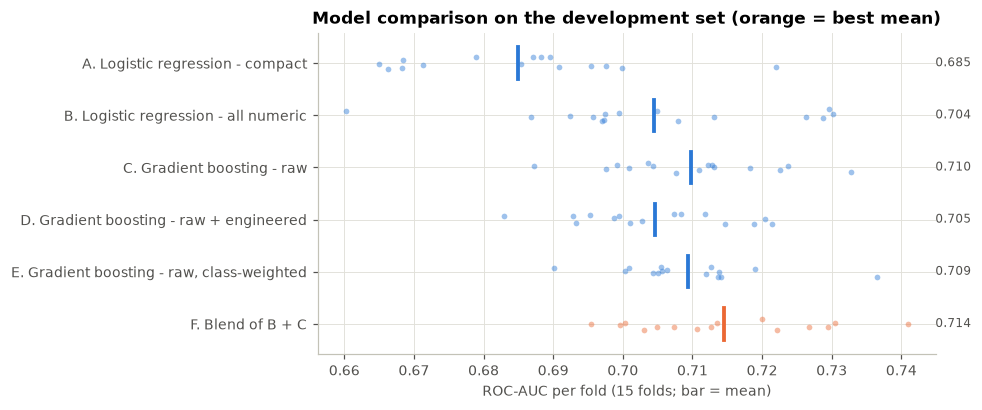

In [48]:
fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(candidates)
rng_jit = np.random.default_rng(0)
for i, n in enumerate(names):
    col = ORANGE if n == best_name else BLUE
    ax.scatter(fold_auc[n], i + rng_jit.uniform(-0.12, 0.12, len(fold_auc)), s=14, color=col, alpha=0.45, linewidths=0)
    ax.plot([fold_auc[n].mean()] * 2, [i - 0.3, i + 0.3], color=col, linewidth=2.5)
    ax.text(fold_auc.values.max() + 0.004, i, f"{fold_auc[n].mean():.3f}", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(names)), names)
ax.invert_yaxis()
ax.set_xlabel("ROC-AUC per fold (15 folds; bar = mean)")
ax.set_title("Model comparison on the development set (orange = best mean)")
plt.tight_layout(); plt.show()

## 24. Model choice

**Chosen model: F, the blend.** It averages the predicted probabilities of gradient boosting on the raw inputs (C) and a strongly regularised logistic regression on all numeric inputs, including the engineered features (B).

* **Best on both ranking metrics:** mean CV ROC-AUC **0.714** (Gini 0.43) and PR-AUC **0.236**.
* **Wins consistently in paired folds:** better than gradient boosting alone in 10 of 15 folds, logistic regression (all numeric) in 13 of 15, and the compact scorecard in all 15.
* **The gain is modest but costs little.** It is about +0.005 AUC over gradient boosting alone, roughly half a paired standard deviation. The added complexity is small: two standard, well-understood models whose probabilities are simply averaged.

**Why not the alternatives**
* **A, compact logistic regression:** the most transparent, but about 0.03 AUC lower (Gini 0.37 vs 0.43), a clear loss of discrimination. It remains a useful **challenger / explainability reference**.
* **D, boosting with engineered features:** worse than boosting on raw inputs (0.705 vs 0.710), consistent with Section 3.2. The engineered features add value through the *linear* half of the blend instead.
* **E, class-weighted boosting:** no ranking gain (0.709 vs 0.710), and it inflates probabilities (holdout Brier 0.18 vs 0.075). **No re-weighting is used**; the imbalance is handled at the decision threshold.

**Settings:** gradient boosting uses learning rate 0.02, 600 trees, 7 leaves per tree and at least 100 applicants per leaf (shallow and heavily regularised). Logistic regression uses C = 0.01 (strong L2 penalty).

## 25. Final evaluation on the untouched holdout

Each model is refitted on the full development set and scored **once** on the holdout. The champion gets 95% bootstrap confidence intervals (1,000 resamples of the holdout).

In [49]:
CHAMPION = "F. Blend of B + C"
holdout_pred, fitted = {}, {}
for name, (model, cols) in candidates.items():
    fitted[name] = clone(model).fit(X_dev[cols], y_dev)
    holdout_pred[name] = fitted[name].predict_proba(X_hold[cols])[:, 1]

holdout_results = pd.DataFrame({n: evaluate(y_hold, p) for n, p in holdout_pred.items()}).T.round(4)
display(holdout_results)

boot_rng = np.random.default_rng(RANDOM_STATE)
yh, ph = y_hold.to_numpy(), holdout_pred[CHAMPION]
boot = []
for _ in range(1000):
    idx = boot_rng.integers(0, len(yh), len(yh))
    boot.append({"ROC_AUC": roc_auc_score(yh[idx], ph[idx]), "PR_AUC": average_precision_score(yh[idx], ph[idx]),
                 "KS": ks_statistic(yh[idx], ph[idx]), "capture_top20%": capture_rate(yh[idx], ph[idx], 0.20)})
boot = pd.DataFrame(boot)
ci = pd.DataFrame({"holdout": pd.Series(evaluate(yh, ph))[boot.columns], "CI_2.5%": boot.quantile(0.025), "CI_97.5%": boot.quantile(0.975)}).round(3)
print(f"Champion: {CHAMPION}")
ci

,ROC_AUC,Gini,PR_AUC,KS,capture_top10%,capture_top20%,Brier
A. Logistic regression - compact,0.6743,0.3486,0.2056,0.2743,0.3011,0.4432,0.0763
B. Logistic regression - all numeric,0.6837,0.3673,0.2136,0.3031,0.3125,0.4489,0.0760
C. Gradient boosting - raw,0.6898,0.3796,0.2427,0.2915,0.3125,0.4205,0.0754
D. Gradient boosting - raw + engineered,0.6869,0.3738,0.2478,0.3034,0.3011,0.4261,0.0753
"E. Gradient boosting - raw, class-weighted",0.6883,0.3765,0.2368,0.2913,0.3011,0.4318,0.1822
F. Blend of B + C,0.6914,0.3828,0.2453,0.2985,0.3125,0.4489,0.0753


Champion: F. Blend of B + C


,holdout,CI_2.5%,CI_97.5%
ROC_AUC,0.691,0.647,0.732
PR_AUC,0.245,0.190,0.312
KS,0.298,0.242,0.382
capture_top20%,0.449,0.373,0.514


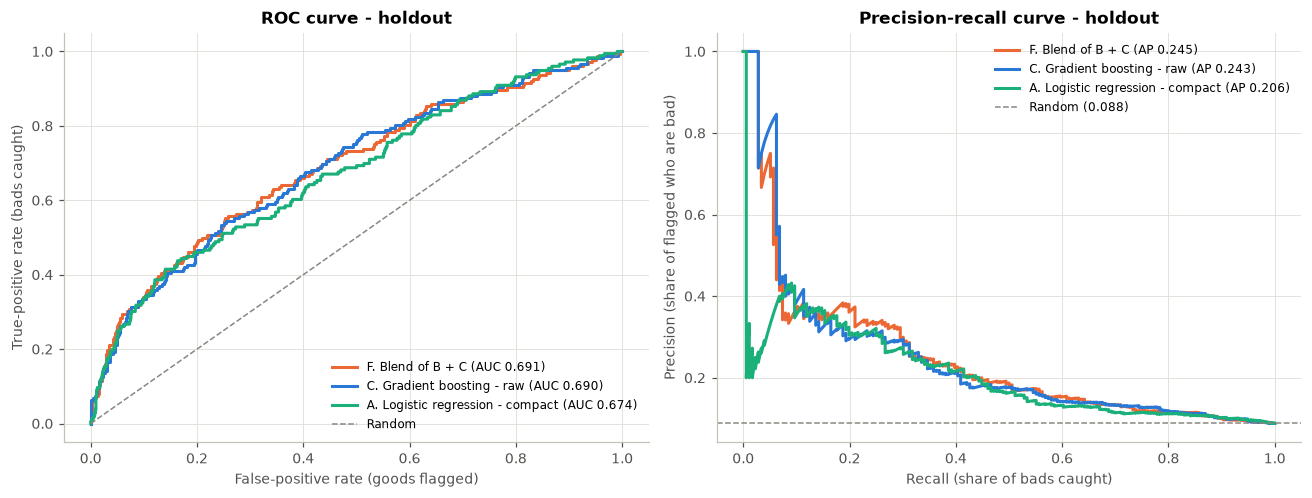

In [50]:
show = {"F. Blend of B + C": ORANGE, "C. Gradient boosting - raw": BLUE, "A. Logistic regression - compact": "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name, col in show.items():
    fpr, tpr, _ = roc_curve(y_hold, holdout_pred[name])
    axes[0].plot(fpr, tpr, color=col, linewidth=2, label=f"{name[:2]} {name[3:]} (AUC {roc_auc_score(y_hold, holdout_pred[name]):.3f})")
    prec, rec, _ = precision_recall_curve(y_hold, holdout_pred[name])
    axes[1].plot(rec, prec, color=col, linewidth=2, label=f"{name[:2]} {name[3:]} (AP {average_precision_score(y_hold, holdout_pred[name]):.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1, label="Random")
axes[0].set_xlabel("False-positive rate (goods flagged)"); axes[0].set_ylabel("True-positive rate (bads caught)")
axes[0].set_title("ROC curve - holdout")
axes[1].axhline(y_hold.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"Random ({y_hold.mean():.3f})")
axes[1].set_xlabel("Recall (share of bads caught)"); axes[1].set_ylabel("Precision (share of flagged who are bad)")
axes[1].set_title("Precision-recall curve - holdout")
for ax in axes:
    ax.legend(frameon=False, fontsize=8, loc="upper right" if ax is axes[1] else "lower right")
plt.tight_layout(); plt.show()

**Score deciles on the holdout.** Decile 1 = the 10% of applicants the champion rates riskiest. The table shows how bads concentrate in the top deciles (lift) and whether average predicted probability tracks the observed bad rate (calibration).

,applicants,bads,bad_rate,mean_predicted,cum_share_of_bads,lift
decile,,,,,,
1,200,55,0.275,0.253,0.312,3.123
2,200,24,0.120,0.140,0.449,1.363
3,200,20,0.100,0.106,0.562,1.136
4,200,14,0.070,0.084,0.642,0.795
5,200,15,0.075,0.069,0.727,0.852
6,199,12,0.060,0.058,0.795,0.685
7,200,11,0.055,0.048,0.858,0.625
8,200,8,0.040,0.040,0.903,0.454
9,200,8,0.040,0.032,0.949,0.454


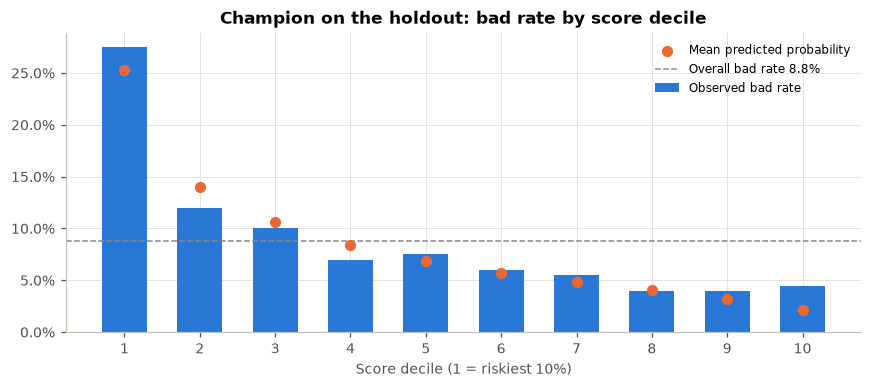

In [51]:
def decile_table(y, p) -> pd.DataFrame:
    d = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    d["decile"] = pd.qcut(pd.Series(p).rank(method="first", ascending=False), 10, labels=range(1, 11)).to_numpy()
    t = d.groupby("decile", observed=True).agg(applicants=("y", "size"), bads=("y", "sum"), bad_rate=("y", "mean"), mean_predicted=("p", "mean"))
    t["cum_share_of_bads"] = t["bads"].cumsum() / t["bads"].sum()
    t["lift"] = t["bad_rate"] / d["y"].mean()
    return t

deciles = decile_table(y_hold, holdout_pred[CHAMPION])
display(deciles.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(deciles.index.astype(int), deciles["bad_rate"], color=BLUE, width=0.6, label="Observed bad rate")
ax.scatter(deciles.index.astype(int), deciles["mean_predicted"], color=ORANGE, s=40, zorder=3, label="Mean predicted probability")
ax.axhline(y_hold.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"Overall bad rate {y_hold.mean():.1%}")
ax.set_xticks(range(1, 11)); ax.set_xlabel("Score decile (1 = riskiest 10%)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Champion on the holdout: bad rate by score decile")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 26. Class imbalance, threshold selection and the business trade-off

A model only produces a risk ranking; the lender must choose **where to cut**. Every cut-off trades two errors:
* **Missed bad borrower (false negative):** the loan is approved and becomes delinquent, losing a large part of the principal plus collection costs.
* **Wrongly declined good borrower (false positive):** a customer who would have repaid is rejected, losing the interest margin and future business, and making the product feel unfair.

To avoid tuning on the holdout, the threshold is chosen from **out-of-fold predictions on the development set**: every development applicant is scored by a model that did not see them. It is then applied once to the holdout.

**Operating points.** Each row is a different cut-off, expressed as the share of applicants declined:

In [52]:
oof_dev = cross_val_predict(clone(candidates[CHAMPION][0]), X_dev, y_dev,
                            cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:, 1]
print(f"Out-of-fold ROC-AUC on development set: {roc_auc_score(y_dev, oof_dev):.3f}")


def confusion_at(y, p, thr) -> dict:
    y, flag = np.asarray(y), np.asarray(p) >= thr
    tp, fp = int((flag & (y == 1)).sum()), int((flag & (y == 0)).sum())
    fn, tn = int((~flag & (y == 1)).sum()), int((~flag & (y == 0)).sum())
    return {"threshold": thr, "decline_rate": flag.mean(), "bads_caught (recall)": tp / (tp + fn),
            "precision": tp / max(tp + fp, 1), "goods_declined (FPR)": fp / (fp + tn),
            "bad_rate_among_approved": fn / max(fn + tn, 1), "goods_declined_per_bad_caught": fp / max(tp, 1),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


operating = pd.DataFrame([confusion_at(y_dev, oof_dev, np.quantile(oof_dev, 1 - r)) for r in (0.05, 0.10, 0.15, 0.20, 0.30, 0.40)])
operating.drop(columns=["TP", "FP", "FN", "TN"]).round(3)

Out-of-fold ROC-AUC on development set: 0.714


,threshold,decline_rate,bads_caught (recall),precision,goods_declined (FPR),bad_rate_among_approved,goods_declined_per_bad_caught
0,0.221,0.05,0.199,0.350,0.036,0.074,1.857
1,0.165,0.10,0.303,0.266,0.081,0.068,2.756
2,0.140,0.15,0.393,0.230,0.127,0.063,3.344
3,0.122,0.20,0.467,0.205,0.174,0.058,3.875
4,0.097,0.30,0.570,0.167,0.274,0.054,4.995
5,0.079,0.40,0.670,0.147,0.374,0.048,5.802


**Choosing the cut-off with an explicit cost assumption.** No loss or margin data was provided, so I assume illustrative economics, stated openly so the business can replace them:
* A **missed bad borrower costs about 5 times** as much as a **wrongly declined good borrower**. For an unsecured personal loan, a default typically loses most of the principal, while a lost good customer costs the net interest margin, a fraction of the principal.
* I also show cost ratios of **3** and **10** to see how sensitive the cut-off is.

The expected cost per applicant is (ratio × missed bads + wrongly declined goods) / applicants. The cut-off that minimises it on the development out-of-fold scores is selected. For reference, if the probabilities were perfectly calibrated, theory gives an optimal probability threshold of 1 / (1 + ratio).

In [53]:
COST_RATIOS = (3, 5, 10)
BASE_COST_RATIO = 5
thr_grid = np.unique(np.quantile(oof_dev, np.linspace(0, 1, 401)))


def expected_cost(y, p, thr, ratio) -> float:
    c = confusion_at(y, p, thr)
    return (ratio * c["FN"] + c["FP"]) / len(y)


rows = []
for ratio in COST_RATIOS:
    costs = np.array([expected_cost(y_dev, oof_dev, t, ratio) for t in thr_grid])
    best_t = thr_grid[costs.argmin()]
    c = confusion_at(y_dev, oof_dev, best_t)
    rows.append({"cost_ratio (bad missed : good declined)": f"{ratio}:1", "theory_threshold 1/(1+r)": 1 / (1 + ratio),
                 "chosen_threshold": best_t, "decline_rate": c["decline_rate"], "bads_caught (recall)": c["bads_caught (recall)"],
                 "goods_declined (FPR)": c["goods_declined (FPR)"], "bad_rate_among_approved": c["bad_rate_among_approved"],
                 "cost_per_applicant": costs.min(), "cost_if_approve_all": ratio * y_dev.mean(),
                 "cost_saving_vs_approve_all_%": 100 * (1 - costs.min() / (ratio * y_dev.mean()))})
threshold_table = pd.DataFrame(rows).set_index("cost_ratio (bad missed : good declined)")
THRESHOLD = float(threshold_table.loc[f"{BASE_COST_RATIO}:1", "chosen_threshold"])
print(f"Chosen probability threshold (cost ratio {BASE_COST_RATIO}:1): {THRESHOLD:.4f}")
threshold_table.round(3)

Chosen probability threshold (cost ratio 5:1): 0.1487


,theory_threshold 1/(1+r),chosen_threshold,decline_rate,bads_caught (recall),goods_declined (FPR),bad_rate_among_approved,cost_per_applicant,cost_if_approve_all,cost_saving_vs_approve_all_%
cost_ratio (bad missed : good declined),,,,,,,,,
3:1,0.250,0.245,0.043,0.184,0.029,0.075,0.241,0.263,8.357
5:1,0.167,0.149,0.130,0.369,0.107,0.064,0.375,0.439,14.672
10:1,0.091,0.119,0.210,0.487,0.183,0.057,0.618,0.878,29.672


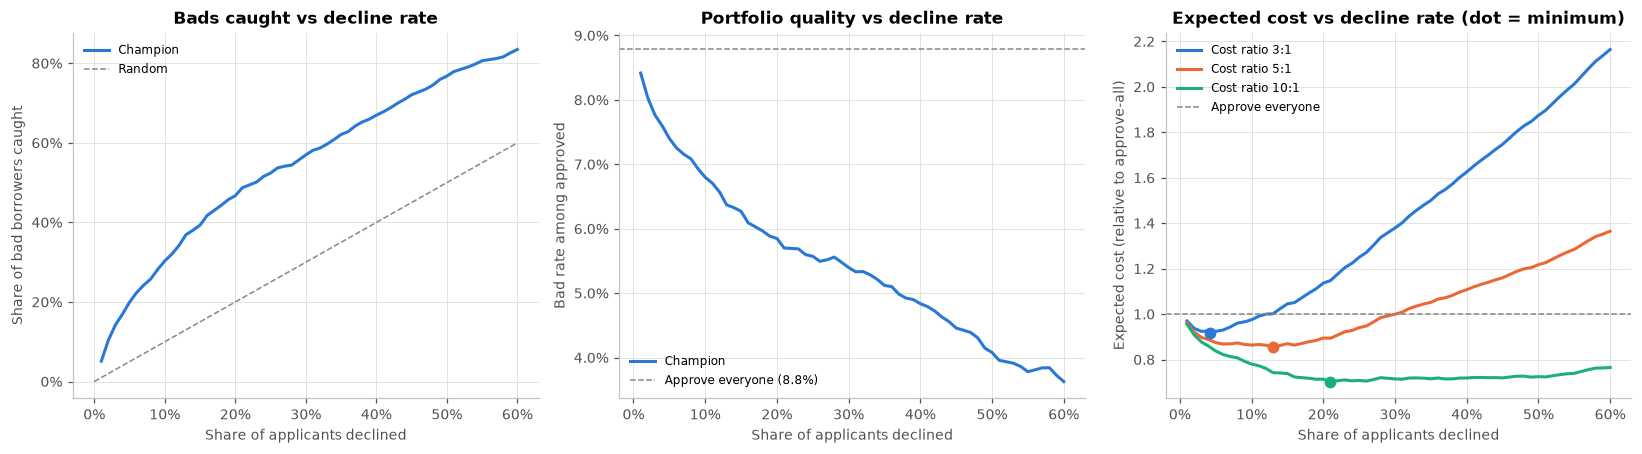

In [54]:
decline = np.linspace(0.01, 0.6, 60)
curve = pd.DataFrame([confusion_at(y_dev, oof_dev, np.quantile(oof_dev, 1 - r)) for r in decline])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

axes[0].plot(curve["decline_rate"], curve["bads_caught (recall)"], color=BLUE, linewidth=2, label="Champion")
axes[0].plot([0, 0.6], [0, 0.6], color=MUTED, linestyle="--", linewidth=1, label="Random")
axes[0].set_xlabel("Share of applicants declined"); axes[0].set_ylabel("Share of bad borrowers caught")
axes[0].set_title("Bads caught vs decline rate")

axes[1].plot(curve["decline_rate"], curve["bad_rate_among_approved"], color=BLUE, linewidth=2, label="Champion")
axes[1].axhline(y_dev.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"Approve everyone ({y_dev.mean():.1%})")
axes[1].set_xlabel("Share of applicants declined"); axes[1].set_ylabel("Bad rate among approved")
axes[1].set_title("Portfolio quality vs decline rate")

for ratio, col in zip(COST_RATIOS, (BLUE, ORANGE, "#1baf7a")):
    cost = [(ratio * r["FN"] + r["FP"]) / len(y_dev) for _, r in curve.iterrows()]
    axes[2].plot(curve["decline_rate"], np.array(cost) / (ratio * y_dev.mean()), color=col, linewidth=2, label=f"Cost ratio {ratio}:1")
    best = threshold_table.loc[f"{ratio}:1"]
    axes[2].scatter(best["decline_rate"], best["cost_per_applicant"] / best["cost_if_approve_all"], color=col, s=45, zorder=3)
axes[2].axhline(1, color=MUTED, linestyle="--", linewidth=1, label="Approve everyone")
axes[2].set_xlabel("Share of applicants declined"); axes[2].set_ylabel("Expected cost (relative to approve-all)")
axes[2].set_title("Expected cost vs decline rate (dot = minimum)")
for ax in axes:
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(frameon=False, fontsize=8)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout(); plt.show()

**Applying the chosen threshold to the holdout** (threshold fixed beforehand from the development set):

In [55]:
h = confusion_at(y_hold, holdout_pred[CHAMPION], THRESHOLD)
cm = pd.DataFrame([[h["TN"], h["FP"]], [h["FN"], h["TP"]]],
                  index=["Actual good (0)", "Actual bad (1)"], columns=["Predicted approve", "Predicted decline"])
display(cm)
summary_h = {k: round(v, 3) for k, v in h.items() if k not in ("TP", "FP", "FN", "TN")}
summary_h["cost_saving_vs_approve_all_%"] = round(100 * (1 - expected_cost(y_hold, holdout_pred[CHAMPION], THRESHOLD, BASE_COST_RATIO)
                                                     / (BASE_COST_RATIO * y_hold.mean())), 1)
pd.Series(summary_h, name="holdout at chosen threshold").to_frame()

,Predicted approve,Predicted decline
Actual good (0),1622,201
Actual bad (1),113,63


,holdout at chosen threshold
threshold,0.149
decline_rate,0.132
bads_caught (recall),0.358
precision,0.239
goods_declined (FPR),0.110
bad_rate_among_approved,0.065
goods_declined_per_bad_caught,3.190
cost_saving_vs_approve_all_%,13.000


## 27. Robustness checks

**(a) Population shift.** Adversarial validation trains a classifier to tell training rows from test rows using the model inputs. AUC ≈ 0.5 would mean the populations look the same.
I then re-weight the holdout so it resembles the test population (weight = odds of "looks like test") and recompute AUC. This estimates performance on test-like applicants, assuming the relationship between features and delinquency is unchanged.

In [56]:
X_adv = pd.concat([X_train, X_test])
y_adv = np.r_[np.zeros(len(X_train)), np.ones(len(X_test))]
adv_oof = cross_val_predict(make_gbm(max_iter=200), X_adv, y_adv, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
                            method="predict_proba")[:, 1]
print(f"Adversarial AUC (train vs test, model inputs): {roc_auc_score(y_adv, adv_oof):.3f}")

drift = {}
for c in X_adv.columns:
    x = X_adv[c].cat.codes if isinstance(X_adv[c].dtype, pd.CategoricalDtype) else X_adv[c].fillna(-999)
    a = roc_auc_score(y_adv, x)
    drift[c] = max(a, 1 - a)
print("Inputs that individually separate train from test the most (univariate AUC):")
display(pd.Series(drift).sort_values(ascending=False).head(8).round(3).to_frame("univariate_AUC"))

p_test_like = pd.Series(adv_oof[: len(X_train)], index=X_train.index).loc[X_hold.index].clip(0.01, 0.99)
w = p_test_like / (1 - p_test_like)
print(f"Effective holdout size after re-weighting: {w.sum() ** 2 / (w ** 2).sum():.0f} of {len(w)}")
pd.DataFrame({"holdout_AUC": {n: roc_auc_score(y_hold, holdout_pred[n]) for n in holdout_pred},
              "test_like_weighted_AUC": {n: roc_auc_score(y_hold, holdout_pred[n], sample_weight=w) for n in holdout_pred}}).round(3)

Adversarial AUC (train vs test, model inputs): 0.696


Inputs that individually separate train from test the most (univariate AUC):


,univariate_AUC
Phone Network.numberBillingType,0.567
Email Attributes.uniqueHits,0.560
fe_email_tenure_days,0.559
Email Attributes.digitalAge,0.554
Email Name Attributes.digitalage,0.551
fe_digital_presence_ratio,0.545
fe_email_phone_age_gap_years,0.542
fe_footprint_score,0.541


Effective holdout size after re-weighting: 1002 of 1999


,holdout_AUC,test_like_weighted_AUC
A. Logistic regression - compact,0.674,0.660
B. Logistic regression - all numeric,0.684,0.684
C. Gradient boosting - raw,0.690,0.696
D. Gradient boosting - raw + engineered,0.687,0.705
"E. Gradient boosting - raw, class-weighted",0.688,0.702
F. Blend of B + C,0.691,0.698


**(b) Dependence on billing type.** Section 3.2 flagged billing type / `fe_is_postpaid` as shifting between train and test. How much does the champion rely on it? (Same 5 folds, with and without those inputs.)

In [57]:
no_billing = ["Phone Network.numberBillingType", "fe_is_postpaid"]
champ_nb = BlendClassifier([c for c in RAW_COLS if c not in no_billing], [c for c in NUMERIC_MODEL_COLS if c not in no_billing],
                           BEST_GBM, BEST_C["all numeric"])
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
with_b = cross_val_score(clone(candidates[CHAMPION][0]), X_dev, y_dev, cv=skf5, scoring="roc_auc")
without_b = cross_val_score(champ_nb, X_dev, y_dev, cv=skf5, scoring="roc_auc")
pd.DataFrame({"with billing inputs": with_b, "without billing inputs": without_b}).agg(["mean", "std"]).round(4)

,with billing inputs,without billing inputs
mean,0.7138,0.7094
std,0.0129,0.0120


## 28. Model development summary

**Validation.** Stratified 80/20 split. Model selection used repeated stratified 5-fold CV on the development set, and the threshold was chosen from development out-of-fold scores. The holdout was scored **once**.

| Metric (champion) | Cross-validation (development, 15 folds) | Holdout (95% bootstrap CI) | Random model |
|---|---|---|---|
| ROC-AUC | 0.714 ± 0.013 | **0.691** (0.647 – 0.732) | 0.50 |
| Gini | 0.43 | 0.38 | 0 |
| PR-AUC | 0.236 | **0.245** (0.190 – 0.312) | 0.088 |
| KS | — | 0.30 (0.24 – 0.38) | 0 |
| Bads captured in riskiest 20% | — | 45% (37% – 51%) | 20% |

* The holdout AUC is a little below CV but **inside its confidence interval**, and every candidate drops by a similar amount with an unchanged ranking. This points to sampling variation (only 176 bads) rather than the champion overfitting.
* **Lift:** the riskiest decile has a 27.5% bad rate, **3.1×** the average; the safest four deciles are at 4–5.5%.
* **Calibration:** mean predicted probability tracks the observed bad rate across deciles (e.g. 25% vs 27.5% in the top decile), with Brier 0.075. The cost-optimal threshold (0.149) is close to the theoretical 1/(1+5) = 0.167, which also suggests reasonable calibration *on this population*. This is not guaranteed on the shifted test population, so the 1–100 output in 3.5 is presented as a relative risk score.

**Threshold and trade-off** (assumed cost ratio 5:1, missed bad vs wrongly declined good):
* Threshold **0.149** declines about **13%** of applicants. On the holdout it catches **36% of bad borrowers** (63 of 176) and wrongly declines **11% of good borrowers** (201): about **3 good applicants declined per bad one caught**.
* The bad rate among approved loans falls from **8.8% to 6.5%**, and expected cost falls by about **13%** vs approving everyone.
* **The cut-off depends heavily on the economics:** at 3:1 only about 4% would be declined; at 10:1 about 21% (catching 49% of bads). It should be re-derived from real loss-given-default and margin figures.
* **Recommendation:** with moderate discrimination (AUC about 0.70), a single hard cut is blunt. A **tiered policy** fits better:
  1. Auto-decline only the riskiest band (about the top 5–10%, where bad rates are 3× average).
  2. Send the next band to manual review, extra verification, or a smaller first loan.
  3. Approve the rest.

**Robustness**
* **Population shift:** a classifier separates train from test with AUC 0.70. The shift is spread across many identity signals (younger emails, fewer hits, thinner footprints, more missing billing type). With the holdout re-weighted to resemble the test population, champion AUC is **0.698** (vs 0.691 unweighted), so there is no sign of degradation. This assumes the feature–delinquency relationship is the same in the test population, which cannot be verified without test labels.
* **Billing type** (flagged in 3.2) adds only about 0.004 AUC; the model does not depend on it heavily.

**Limitations:** no time dimension (no out-of-time test); a small number of bads (wide confidence intervals); an assumed cost ratio; an identity-only feature set that caps discrimination at about 0.70 AUC. For scoring (3.5), the champion is **refitted on all labelled data** with the same settings.

In [58]:
# Hand-off to scoring (3.5): the champion specification and the decision threshold
FINAL_MODEL = clone(candidates[CHAMPION][0])     # refitted on all labelled data before scoring the test set
print("Final model:", CHAMPION)
print("  gradient boosting settings:", BEST_GBM, "| logistic regression C:", BEST_C["all numeric"])
print(f"  decision threshold (cost ratio {BASE_COST_RATIO}:1): {THRESHOLD:.4f}")

Final model: F. Blend of B + C
  gradient boosting settings: {'learning_rate': 0.02, 'max_iter': 600, 'max_leaf_nodes': 7, 'min_samples_leaf': 100} | logistic regression C: 0.01
  decision threshold (cost ratio 5:1): 0.1487


# Part 4 — Results Interpretation (3.4)

This part brings together what the analysis found. Sections 29 and 32 summarise results already established in 3.1–3.3.
Sections 30–31 add one new piece of analysis: **which inputs the chosen model actually relies on**, measured on the untouched holdout. That evidence is needed to name the strongest signals and to judge which engineered features were useful, so the strongest signals come before the engineered features here.

## 29. Key data-quality observations

| # | Observation | Evidence (Part 1) | What it meant for the results |
|---|---|---|---|
| 1 | **Missing values were disguised.** Missing is written as the text `"NaT"`, and a second code, `-1`, means "not found in the Bureau network" | 0 true NaN on load, but up to 100% `"NaT"` in some columns; 50 columns of mixed type; `-1` in up to 84% of email-name fields | Without cleaning, numeric fields would have been read as text. `standardise()` restores proper types |
| 2 | **Missingness carries signal.** Whole blocks of a service go missing together, and the bad rate differs between missing and present | e.g. email-name age not found: 9.8% bad vs 3–6% when found (Section 30) | Missing is **kept as information** (own bin, missing-indicator columns), never silently imputed. Several of the strongest signals are really "was this person found?" signals |
| 3 | **Small, imbalanced, partly unlabelled target** | 9,114 good / 878 bad / 8 `"NaT"`; bad rate 8.8% | The 8 unlabelled rows are excluded. Ranking metrics (ROC-AUC, PR-AUC, KS) replace accuracy; the cut-off is chosen explicitly; confidence intervals are wide (176 holdout bads) |
| 4 | **Dead and duplicated columns** | 7 constant columns; 2 identical pairs; `Email GIN.fraud` never 1, `fraudNetwork` 1 in 7 rows | Dropped or ignored. The fraud flags provide **no usable fraud signal** in this sample |
| 5 | **Implausible and artificial values** | Phone ages of about 100 years; identity-graph counts near 500; 37% of email ages exactly 181 days (a system date, not a real first-use date) | Phone age capped at 30 years; email tenure uses the **older** of the two email ages, so the 181-day pile-up does not masquerade as "new email" |
| 6 | **Strong train → test population shift** | Carrier Airtel 94% → 45%; billing type missing 4% → 23%; adversarial AUC 0.70 | Carrier and region **excluded** as inputs. Holdout re-weighted to look like test: AUC holds (0.698). The main risk to the delivered scores |
| 7 | **Clean on duplicates** | No duplicate rows, no repeat applicants, no train/test overlap | No action needed |
| 8 | **What is not in the data** | No loan amount, income, bureau history or repayment behaviour; no application date | Caps discrimination at about AUC 0.70, and rules out out-of-time validation |

**Assumptions carried through:** `Target = 1` means delinquent (definition and observation window not provided); `-1` in age and score fields means "not found"; meanings of undocumented columns as listed in Section 2.

## 30. Strongest predictive signals

**Method: permutation importance on the holdout.** Each input is shuffled in turn, which breaks its link with delinquency while keeping its distribution. The holdout is re-scored and the lost ROC-AUC is recorded (10 shuffles per input).
* It works on the **blend as a whole** (both halves), and it measures signal that **generalises to unseen applicants**, not what the model memorised.
* **Caveat:** correlated inputs share the credit. Shuffling one email-age column leaves the others intact, so each looks less important than the information it carries. That is why I also shuffle **whole signal families** together (second table).

In [ ]:
def permutation_auc_drop(model, X, y, groups: dict, n_repeats: int = 10, seed: int = RANDOM_STATE) -> pd.DataFrame:
    """Holdout ROC-AUC lost when the columns in each group are shuffled together (same row order for every column)."""
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    rows = {}
    for name, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            idx = rng.permutation(len(X))
            Xp = X.copy()
            for c in cols:
                Xp[c] = X[c].iloc[idx].set_axis(X.index)
            drops.append(base - roc_auc_score(y, model.predict_proba(Xp)[:, 1]))
        rows[name] = {"AUC_drop": np.mean(drops), "AUC_drop_std": np.std(drops), "n_inputs": len(cols)}
    return pd.DataFrame(rows).T.sort_values("AUC_drop", ascending=False)


champion_fit = fitted[CHAMPION]
input_importance = permutation_auc_drop(champion_fit, X_hold, y_hold, {c: [c] for c in X_hold.columns})
input_importance["rank"] = np.arange(1, len(input_importance) + 1)
input_importance["engineered"] = input_importance.index.isin(ENGINEERED)
print(f"Champion holdout ROC-AUC: {roc_auc_score(y_hold, holdout_pred[CHAMPION]):.3f}")
print(f"Inputs whose shuffling costs at least 0.002 AUC: {(input_importance['AUC_drop'] >= 0.002).sum()} of {len(input_importance)}")
input_importance.head(15).round(4)

In [ ]:
top = input_importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(range(len(top)), top["AUC_drop"], xerr=top["AUC_drop_std"], color=[ORANGE if e else BLUE for e in top["engineered"]],
        height=0.6, error_kw=dict(ecolor=MUTED, lw=1))
ax.set_yticks(range(len(top)), top.index)
ax.set_xlabel("Holdout ROC-AUC lost when the input is shuffled (mean ± sd over 10 shuffles)")
ax.set_title("Strongest individual inputs in the champion (orange = engineered)")
ax.axvline(0, color=MUTED, linewidth=0.8)
plt.tight_layout(); plt.show()

**Signal families.** Related inputs (raw and engineered) are shuffled together. `share_of_AUC_above_random_%` = AUC lost ÷ (holdout AUC − 0.5); it shows how much of the model's lift each family carries. The shares are not additive, because families overlap in what they measure.

In [ ]:
SIGNAL_FAMILIES = {
    "Email age / tenure": ["Email Attributes.digitalAge", "Email Name Attributes.digitalage", "Email Name Attributes.emailNameDigitalAge",
                           "fe_email_tenure_days", "fe_email_new_at_application", "fe_email_phone_age_gap_years"],
    "Social & platform presence": [c for c in X_hold.columns if "Social Advance." in c] + ["fe_digital_presence_ratio"],
    "Digital footprint strength": ["Email Attributes.footprint", "Email Attributes.uniqueHits", "Email Name Attributes.emailFootprintStrength",
                                   "Phone Name Attributes.phoneFootprintStrengthOverall", "fe_footprint_score", "fe_identity_not_found_count"],
    "Phone age & name link": ["Phone Name Attributes.digitalage", "Phone Name Attributes.phoneNameDigitalAge",
                              "Phone Name Attributes.revocationHistory", "fe_phone_name_tenure_level"],
    "Identity graph (GIN)": [c for c in X_hold.columns if "GIN." in c],
    "Name matching": [c for c in X_hold.columns if c.startswith("Email Name Attributes.")
                      and c not in ("Email Name Attributes.digitalage", "Email Name Attributes.emailNameDigitalAge",
                                    "Email Name Attributes.emailFootprintStrength")],
    "Email validity & domain": ["Email Attributes.emailExists", "Email Attributes.domainExists", "Email Attributes.domainRiskLevel",
                                "Email Attributes.domaincorporate", "Email Attributes.emailFinalRecommendation"],
    "Phone network & billing": [c for c in X_hold.columns if c.startswith("Phone Network.")] + ["fe_is_postpaid"],
}
assigned = [c for cols in SIGNAL_FAMILIES.values() for c in cols]
assert sorted(assigned) == sorted(X_hold.columns), set(X_hold.columns) ^ set(assigned)
family_importance = permutation_auc_drop(champion_fit, X_hold, y_hold, SIGNAL_FAMILIES, n_repeats=20)
family_importance["share_of_AUC_above_random_%"] = 100 * family_importance["AUC_drop"] / (roc_auc_score(y_hold, holdout_pred[CHAMPION]) - 0.5)
family_importance.round(4)

**Which way do the strongest inputs point?** Bad rate by group for the 8 most important inputs, on all labelled rows:

In [ ]:
def signal_bins(x: pd.Series) -> pd.Series:
    """Bins for describing a signal: categories as they are, numerics via the Section 14 binning; missing gets its own bin."""
    if isinstance(x.dtype, pd.CategoricalDtype):
        return x.astype(object).where(x.notna(), "missing")
    return fe_bins(x, x)


TOP_SIGNALS = input_importance.head(8).index.tolist()
signal_rows = {}
for c in TOP_SIGNALS:
    g = y_train.groupby(signal_bins(X_train[c]), observed=True).agg(["size", "mean"]).query("size >= 50")
    lo, hi = g["mean"].idxmin(), g["mean"].idxmax()
    signal_rows[c] = {"AUC_drop": input_importance.loc[c, "AUC_drop"], "missing_%": 100 * X_train[c].isna().mean(),
               "safest_group": f"{lo} ({g.loc[lo, 'mean']:.1%}, n={g.loc[lo, 'size']:,})",
               "riskiest_group": f"{hi} ({g.loc[hi, 'mean']:.1%}, n={g.loc[hi, 'size']:,})"}
print(f"Overall bad rate (all labelled rows): {y_train.mean():.1%}. Groups with fewer than 50 applicants are ignored.")
pd.DataFrame(signal_rows).T.astype({"AUC_drop": float, "missing_%": float}).round({"AUC_drop": 4, "missing_%": 1})

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.8))
for ax, c in zip(axes.ravel(), TOP_SIGNALS):
    g = y_train.groupby(signal_bins(X_train[c]), observed=True).agg(["size", "mean"]).query("size >= 50")
    ax.bar(range(len(g)), g["mean"], color=[MUTED if i == "missing" else BLUE for i in g.index], width=0.6)
    ax.axhline(y_train.mean(), color=ORANGE, linestyle="--", linewidth=1.5, zorder=0)
    for i, (n, r) in enumerate(g[["size", "mean"]].values):
        ax.text(i, r, f"{r:.1%}\nn={n:,.0f}", ha="center", va="bottom", fontsize=7, color=INK)
    ax.set_xticks(range(len(g)), g.index, rotation=30, ha="right", fontsize=7)
    ax.set_ylim(0, g["mean"].max() * 1.35)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(c, fontsize=9)
fig.suptitle(f"Bad rate by group for the 8 strongest inputs (dashed orange = overall {y_train.mean():.1%}; grey bar = missing)", fontweight="bold")
plt.tight_layout(); plt.show()

**Cross-check with the logistic half of the blend.** Standardised coefficients (effect per standard deviation, holding the other inputs fixed), compared with each input's direction on its own:

In [ ]:
logit_pipe = champion_fit.logit_
coef = pd.Series(logit_pipe[-1].coef_[0], index=logit_pipe[:-1].get_feature_names_out(NUMERIC_MODEL_COLS))
coef.index = coef.index.str.replace("missingindicator_", "[missing] ", regex=False)
top_coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)


def univariate_spearman(name: str) -> float:
    if name.startswith("[missing] "):
        return X_train[name.removeprefix("[missing] ")].isna().astype(float).corr(y_train, method="spearman")
    return X_train[name].corr(y_train, method="spearman")


uni = pd.Series({n: univariate_spearman(n) for n in top_coef.index})
pd.DataFrame({"coefficient (per sd)": top_coef.round(3), "effect in model": np.where(top_coef > 0, "raises risk", "lowers risk"),
              "univariate_spearman": uni.round(3), "same_sign_as_univariate": np.sign(top_coef) == np.sign(uni)})

**What the model relies on**

1. **Being on WhatsApp is by far the strongest single signal.** Applicants whose phone is *not* on WhatsApp (5.9% of applicants) default at **32%**, 3.6× the average, against 7.2% for those on it. Shuffling this one input costs **0.052 AUC**, about **27%** of the model's whole lift above random. In India, a phone without WhatsApp is most likely secondary, recently acquired or inactive: a weak link to a real, settled person.
2. **Social and platform presence as a whole is the dominant family** (about **54%** of the lift). Use of everyday consumer platforms marks an established, active identity:
   * Flipkart account on the email: 5.5% bad vs 10.9% without.
   * Any Skype result: 2.6–2.7% bad, although only 3.4% of applicants have one.
3. **Email age and tenure is the second family** (about **18%**). Older emails are safer (5.2% bad above about 6 years vs 12.3% below 1.5 years). Emails the name-email check **cannot find** are riskier (9.8–12.8% bad). A long-lived email is costly to fake.
4. **Phone billing type** adds a little (about 4–5% with the other network fields). Postpaid is 4.0% bad vs 9.2% prepaid; postpaid requires a credit or KYC check by the telecom operator. The rare `"unknown"` billing value has 48% bad, but only 52 applicants.
5. **Weak contributors despite many columns:** the identity graph (15 GIN columns), name matching (8 columns) and email validity/domain checks **each carry about 1% or less** of the lift. `Mobile GIN.l2Confidence` ranks 6th but shows no pattern on its own (8.8% in both groups). Its small effect works through interactions in the boosted trees, and it should be treated as weak.

**Reading the coefficients carefully.** 10 of the 12 largest logistic coefficients point the same way as the input does on its own. The two exceptions, `firstNameMatch` and `Mobile GIN.l2Count`, flip because they overlap heavily with other name-match and graph columns. Their coefficients are *conditional* effects and should not be read individually.

**Overall picture:** the model scores **how established and verifiable an applicant's digital identity is**. Thin, new or unfindable identities are riskier. These are **predictive, not causal** relationships: closing a WhatsApp account does not make anyone a worse borrower. Some of these signals (platform use, postpaid plans) also track income, age and urban location, so a **fairness review** is needed before use in lending decisions.

## 31. The most useful engineered features

How the 8 engineered features from 3.2 performed, on their own (IV, stability) and inside the champion (permutation rank, logistic coefficient):

In [ ]:
fe_in_model = pd.DataFrame({
    "IV (3.2)": fe_eval.loc[ENGINEERED, "IV"],
    "PSI train→test (3.2)": fe_eval.loc[ENGINEERED, "PSI_train_to_test"],
    "permutation_rank (of 84)": input_importance.loc[ENGINEERED, "rank"].astype(int),
    "AUC_drop": input_importance.loc[ENGINEERED, "AUC_drop"].astype(float).round(4),
    "logit_coefficient (per sd)": coef.reindex(ENGINEERED).round(3),
}).sort_values("permutation_rank (of 84)")
engineered_block = permutation_auc_drop(champion_fit, X_hold, y_hold, {"all 8 engineered features": ENGINEERED}, n_repeats=20)
print("AUC lost when all 8 engineered features are shuffled together:",
      f"{engineered_block['AUC_drop'].iloc[0]:.4f} ± {engineered_block['AUC_drop_std'].iloc[0]:.4f}")
fe_in_model

**Most useful, and why**

| Feature | Why it was built | Evidence it helped |
|---|---|---|
| `fe_digital_presence_ratio` | Share of checked platforms where the applicant is present. One stable summary of 34 sparse 0/1 flags, and it handles "service not returned" correctly (the ratio ignores missing platforms) | **Highest IV of all features (0.21)**: 15.8% bad in the least-present fifth vs about 5.6% in the most-present. Ranked in the top 25 inputs inside the champion |
| `fe_email_tenure_days` | Takes the older of the two email ages. This repairs the 181-day system-date pile-up and fills gaps when one source has no age | IV 0.19, **higher than either raw email age**. 7th-largest logistic coefficient (−0.11) |
| `fe_is_postpaid` | Postpaid requires a credit or KYC check by the operator, a sign of stability that the raw 4-level category hides | **3rd-largest logistic coefficient (−0.15)**. Caveat: postpaid share falls 15% → 7% in test (PSI 0.06), so watch it |
| `fe_email_phone_age_gap_years` | An email much younger than the phone suggests a recently created email used for the application | IV 0.12, steadily rising risk (5.4% → 12.3%). Ranked 21st of 84 in the champion |
| `fe_identity_not_found_count`, `fe_footprint_score` | Pool 6 "found?" lookups / 2 footprint ratings into one count or score | IV 0.14 / 0.13; the footprint score beats its best raw input. Smaller role in the champion, where the raw columns are also present |

**What they add overall.** Shuffling all 8 together costs **0.0096 ± 0.0045 AUC**, about 5% of the model's lift. Their individual permutation scores are small for two structural reasons:
* The boosted-tree half of the blend uses **raw inputs only** (3.3 showed trees gain nothing from them).
* Each engineered feature overlaps with the raw columns it was built from.

Their value lies in the **linear half**. Adding that half lifts cross-validated AUC from 0.710 to 0.714, and it is where the coefficient check above finds three engineered features among the strongest effects. Every engineered feature is stable (PSI < 0.1), points in the expected direction and has a one-line business meaning. So they also give the explainability layer: the compact 9-feature scorecard (candidate A) reaches AUC 0.68 using them alone.

**Least useful:** `fe_email_new_at_application`. The effect is real (18.5% vs 8.4% bad) but applies to only 3.7% of applicants, and it is largely captured by email tenure.

## 32. Validation methodology and model performance

**Methodology (Section 19)**
* **No application date** → no out-of-time test possible. **Unlabelled test file** → all evaluation uses the 9,992 labelled rows.
* **Stratified 80/20 split.** Every choice (algorithm, hyperparameters, class weighting, cut-off) was made on the **development** 80%, using repeated stratified 5-fold CV with **paired** fold-by-fold comparisons.
* The cut-off was chosen from **out-of-fold** development scores.
* The **holdout** 20% (176 bads) was scored **once**, with bootstrap confidence intervals.
* All preprocessing is fitted **inside each fold**, so nothing leaks.
* A **test-like re-weighting** of the holdout (from adversarial validation) checks robustness to the population shift.

**Results at a glance (champion: blend of gradient boosting + logistic regression)**

In [ ]:
p_champ = holdout_pred[CHAMPION]
top_decile = deciles.iloc[0]
pct = lambda v: f"{v:.1%}"
glance = pd.DataFrame([
    ("Cross-validated ROC-AUC (development, 15 folds)", f"{comparison.loc[CHAMPION, 'ROC_AUC_mean']:.3f} ± {comparison.loc[CHAMPION, 'ROC_AUC_std']:.3f}"),
    ("Holdout ROC-AUC (95% bootstrap CI)", f"{ci.loc['ROC_AUC', 'holdout']:.3f} ({ci.loc['ROC_AUC', 'CI_2.5%']:.3f} - {ci.loc['ROC_AUC', 'CI_97.5%']:.3f})"),
    ("Holdout Gini", f"{holdout_results.loc[CHAMPION, 'Gini']:.2f}"),
    (f"Holdout PR-AUC (random = {y_hold.mean():.3f})", f"{ci.loc['PR_AUC', 'holdout']:.3f} ({ci.loc['PR_AUC', 'CI_2.5%']:.3f} - {ci.loc['PR_AUC', 'CI_97.5%']:.3f})"),
    ("Holdout KS", f"{ci.loc['KS', 'holdout']:.2f}"),
    ("Share of bads in the riskiest 20% (random = 20%)", pct(ci.loc["capture_top20%", "holdout"])),
    ("Riskiest decile: bad rate / lift", f"{pct(top_decile['bad_rate'])} / {top_decile['lift']:.1f}x"),
    ("Brier score", f"{holdout_results.loc[CHAMPION, 'Brier']:.3f}"),
    (f"Decision threshold (cost ratio {BASE_COST_RATIO}:1)", f"{THRESHOLD:.3f}"),
    ("At threshold: declined / bads caught / goods declined", f"{pct(h['decline_rate'])} / {pct(h['bads_caught (recall)'])} / {pct(h['goods_declined (FPR)'])}"),
    ("At threshold: bad rate among approved (approve-all)", f"{pct(h['bad_rate_among_approved'])} ({pct(y_hold.mean())})"),
    ("At threshold: expected-cost saving vs approve-all", f"{summary_h['cost_saving_vs_approve_all_%']:.0f}%"),
    ("Adversarial AUC, train vs test (0.5 = no shift)", f"{roc_auc_score(y_adv, adv_oof):.3f}"),
    ("Holdout ROC-AUC re-weighted to resemble test", f"{roc_auc_score(y_hold, p_champ, sample_weight=w):.3f}"),
], columns=["measure", CHAMPION]).set_index("measure")
glance

**What the numbers say**
* **Moderate, real discrimination.** Holdout AUC 0.69 (Gini 0.38), with the whole 95% interval well above 0.5. The holdout sits slightly below CV (0.714) but inside its interval, and all six candidates dropped by similar amounts in an unchanged order. This points to sampling noise, not overfitting.
* **Useful concentration of risk.** The riskiest 10% of applicants default at 27.5% (3.1× average). The riskiest 20% contain 45% of all bads. The safest 40% default at only 4–5.5%.
* **Probabilities are usable.** Predicted and observed bad rates agree by decile (Brier 0.075). The cost-optimal cut-off (0.149) is close to the theoretical 1/(1+5) = 0.167.
* **Business value at the 5:1 cost assumption.** Declining 13% of applicants catches 36% of bads and lowers the approved-book bad rate from 8.8% to 6.5%, at the price of about 3 good applicants declined per bad one caught. Expected cost falls by 13%.
* **Robust to the known shift.** Re-weighted to look like the test population, holdout AUC is 0.698. This assumes the feature–delinquency relationship itself has not changed, which cannot be verified without test labels.
* **The ceiling is the data, not the method.** Six quite different models all land between about 0.67 and 0.71 AUC. The limit comes from having only identity and digital-footprint inputs.

## 33. Summary of findings

1. **Data quality.** The raw files needed careful decoding: disguised missing values, two kinds of "absent", artificial dates and dead columns. Missingness turned out to be **informative**, so it was kept as signal. The biggest risk is the **population shift** between train and test (carrier mix, missing billing type). It was handled by excluding unstable inputs and testing a re-weighted holdout, and it should be monitored in production.
2. **Engineered features.** The most useful were **digital presence ratio**, **email tenure**, **postpaid flag** and **email–phone age gap**: business-motivated, stable and monotonic. They improve the **linear model and the blend**, not the boosted trees, and they provide the explainable layer of the model.
3. **Strongest signals.** **WhatsApp presence** (32% bad when absent), broader **social/platform presence**, and **email age** together carry around 70% of the model's lift. The model essentially measures **how established and verifiable a digital identity is**. These are predictive proxies, not causes, and they need a fairness review.
4. **Validation and performance.** Selection by repeated, paired CV; one untouched holdout. Result: **AUC 0.69 (0.65–0.73)**, top-decile lift 3.1×, 45% of bads in the riskiest 20%. Stable under a test-like re-weighting. Best used as a **tiered policy** (decline the top band, review the next band) rather than a single hard cut.

**Limitations and next steps:**
* No out-of-time test.
* Few bads, so wide confidence intervals.
* Assumed cost ratio, to be replaced with real loss and margin figures.
* No credit-history inputs.
* Unverified behaviour on the shifted test population: monitor score distribution (PSI) and early delinquency after deployment, and re-validate once test-period outcomes are known.
* Adding bureau or transaction data is the most promising route to better discrimination.